# Hackathon retail sets — EDA of Set C and Set D

The same kind of exploration as `set_a_b_test_analysis.ipynb`, now for the two remaining chains:

| Set | Files | Grain |
|---|---|---|
| **C** | `daily` | one row per store × article × day (sales, discount, stock, recency, phasing-out flag) |
| **D** | `sales`, `stock` | sales lines per store × article × day × sales type; stock on hand per store × article over date intervals |

**Contents**
0. Setup and helpers
1. Load and fix data types
2. Overview and column profiles
3. **Part I — Set C**: grain → code columns → hierarchy & stores → demand over time → distribution & outliers → prices & discounts → stock → summary
4. **Part II — Set D**: grain → sales types & returns → hierarchy → demand over time → sparsity by aggregation level → prices & margin → stock intervals → summary
5. **Part III — C, D and the test shop side by side** (weekly demand patterns)

## Key findings

**Set C** (daily store × article, 29 stores, 338 articles, 851 pairs, 2023-12-31 → 2026-04-20)
- **Not a full grid**: only 69% of possible pair-days have a row. Pairs drop out for weeks and 57% are gone before the end, so a missing row is not the same as zero sales.
- **Very sparse**: 94% of rows are 0, and a typical pair sells one unit every ~17 days. **Summer (June) is the main peak** in both years, with a smaller Christmas peak. Fri/Sat are the strongest days.
- **Columns that need care**: `is_phasing_out` is never true on a sale day (it leaks the target). `on_hand` does not move with sales and covers years of demand. One article (PROD-0000202, store STR-022, price 0.91) produces all the extreme rows, including a 292-unit day.

**Set D** (sales lines + stock intervals, 40 stores, 2,326 articles, 30 suppliers, 2025-06-01 → 2026-04-24)
- **Only transactions are stored**. A store × article sells on a median of 2 days in 11 months, which is far too sparse to forecast at that level. **Article × week (chain)** is the usable level.
- **Strong retail calendar**: closed on 27 Nov and 25 Dec, peaks on 28 Nov (Black Friday), in the Christmas run-up (24 Dec is the biggest day), around 14 Feb and in late August. Saturday sells ~2.5× Monday.
- **Sales type drives price and margin**: 75% of units sell at full price and 19% on promo. Markdown tier 2 and clearance sell below cost. `stock` is a validity-interval table (one row per stock or price change). It covers only 74% of sales dates and starts almost empty, so treat it as a soft signal.

**Compared with the test shop**: at weekly level, *Set D aggregated to article × chain* looks most like the test shop (50% vs 58% zero weeks, a similar mix of demand classes). Set C store × article and Set D store × article series are much sparser (74% and 92% zero weeks).

## 0. Setup and helpers

In [1]:
%pip install -q numpy pandas matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\mehme\Desktop\Projects\District19\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# Works whether the kernel starts in the notebook folder or the project root
BASE = Path('.') if Path('set-c').exists() else Path('data/hackathon-retail-sets')

# Plot style: same as the Set A/B notebook
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]  # fixed categorical order
plt.rcParams.update({
    'figure.figsize': (11, 4), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'axes.prop_cycle': plt.cycler(color=CAT),
})
HIST = dict(color=BLUE, edgecolor='white', linewidth=0.5)
PAIR = ['store_id', 'article_id']

In [3]:
# ---- Helpers used throughout the notebook ----

def overview(sets):
    """One row per table: size, memory, missing cells, duplicates."""
    rows = []
    for set_name, tables in sets.items():
        for name, df in tables.items():
            rows.append({
                'set': set_name, 'table': name,
                'rows': len(df), 'columns': df.shape[1],
                'memory_MB': round(df.memory_usage(deep=True).sum() / 1e6, 2),
                'missing_cells': int(df.isna().sum().sum()),
                'missing_%': round(100 * df.isna().sum().sum() / df.size, 2),
                'duplicate_rows': int(df.duplicated().sum()),
                'column_names': ', '.join(df.columns),
            })
    return pd.DataFrame(rows)


def profile(df):
    """One row per column: dtype, missing, cardinality, range, examples."""
    out = []
    for c in df.columns:
        s = df[c]
        is_num = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        is_dt = pd.api.types.is_datetime64_any_dtype(s)
        out.append({
            'column': c, 'dtype': str(s.dtype),
            'non_null': int(s.notna().sum()),
            'missing_%': round(100 * s.isna().mean(), 2),
            'n_unique': int(s.nunique()),
            'unique_%': round(100 * s.nunique() / max(len(s), 1), 2),
            'min': s.min() if (is_num or is_dt) else None,
            'max': s.max() if (is_num or is_dt) else None,
            'mean': round(s.mean(), 3) if is_num else None,
            'zeros_%': round(100 * (s == 0).mean(), 2) if is_num else None,
            'examples': ', '.join(map(str, s.dropna().unique()[:5])),
        })
    return pd.DataFrame(out)


def to_week(dates):
    """Monday of the week (same convention as the test shop's week_start)."""
    return dates.dt.to_period('W-SUN').dt.start_time


def sb_label(adi, cv2):
    """Syntetos-Boylan demand class from ADI (avg. weeks between sales) and CV² of non-zero sizes."""
    return np.select([(adi < 1.32) & (cv2 < 0.49), (adi >= 1.32) & (cv2 < 0.49), adi < 1.32],
                     ['smooth', 'intermittent', 'erratic'], 'lumpy')


def demand_classes(df, keys, date_col, end):
    """Weekly demand stats per series. A series runs from its first sale week to `end`
    (a date, or a Series of dates indexed by `keys`); weeks without a sale count as 0."""
    w = df.assign(week=to_week(df[date_col])).groupby([*keys, 'week'])['units'].sum()
    w = w[w > 0].reset_index()
    g = w.groupby(keys)
    end_week = to_week(end) if isinstance(end, pd.Series) else to_week(pd.Series([end]))[0]
    st = pd.DataFrame({'nonzero_weeks': g.size(), 'units': g['units'].sum(),
                       'mean_nz': g['units'].mean(), 'std_nz': g['units'].std()})
    st['span_weeks'] = ((end_week - g['week'].min()).dt.days // 7 + 1).clip(lower=st.nonzero_weeks)
    st['adi'] = st.span_weeks / st.nonzero_weeks
    st['cv2'] = (st.std_nz / st.mean_nz).pow(2).fillna(0)
    st['class'] = sb_label(st.adi, st.cv2)
    return st


def corr_heatmap(df, title):
    num = df.select_dtypes('number').loc[:, lambda d: d.nunique() > 1]
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(1 + 0.8 * len(corr), 0.6 + 0.7 * len(corr)))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(corr)), corr.columns); ax.grid(False)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f'{corr.iat[i, j]:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title(title)
    plt.tight_layout(); plt.show()

## 1. Load and fix data types

In [4]:
c_daily = pd.read_parquet(BASE / 'set-c' / 'daily.parquet')
d_sales = pd.read_parquet(BASE / 'set-d' / 'sales.parquet')
d_stock = pd.read_parquet(BASE / 'set-d' / 'stock.parquet')

# What the raw columns actually contain (dtype 'object' hides the Python type)
raw_types = lambda df: {c: type(df[c].dropna().iloc[0]).__name__ for c in df.columns if df[c].dtype == object}
print('Set C object columns:', raw_types(c_daily))
print('Set D sales date dtype:', d_sales['date'].dtype, '| stock dates:', d_stock['start_date'].dtype, d_stock['end_date'].dtype)
print('Set D stock end_date sentinel rows (9999-12-31):', (d_stock.end_date == '9999-12-31').sum())

Set C object columns: {'date': 'date', 'is_return': 'Decimal', 'units': 'Decimal', 'sales_amount': 'Decimal', 'cogs': 'Decimal', 'discount_amount': 'Decimal', 'discount_pct': 'Decimal', 'on_hand': 'Decimal', 'unit_cost': 'Decimal', 'unit_price': 'Decimal', 'latest_on_hand': 'Decimal', 'last_receipt_date': 'date', 'last_sold_date': 'date', 'days_since_receipt': 'Decimal', 'days_since_sale': 'Decimal'}
Set D sales date dtype: str | stock dates: str str
Set D stock end_date sentinel rows (9999-12-31): 22701


- **Set C** stores numbers as Python `Decimal` objects and dates as `datetime.date` objects. Both are slow and break numeric operations, so they are converted to `float` and `datetime64`.
- **Set D** stores dates as strings. In `stock`, every row is a validity interval (`start_date` → `end_date`). An `end_date` of `9999-12-31` means *still valid*. It is kept as an `is_open` flag, and the date is capped at the last day with data so that date arithmetic works.

In [5]:
# ---- Set C ----
C_NUM = ['is_return', 'units', 'sales_amount', 'cogs', 'discount_amount', 'discount_pct', 'on_hand',
         'unit_cost', 'unit_price', 'latest_on_hand', 'days_since_receipt', 'days_since_sale']
c_daily[C_NUM] = c_daily[C_NUM].astype(float)
c_daily['is_return'] = c_daily['is_return'].astype(int)
for col in ['date', 'last_receipt_date', 'last_sold_date']:
    c_daily[col] = pd.to_datetime(c_daily[col])
c_daily = c_daily.sort_values([*PAIR, 'date']).reset_index(drop=True)

# ---- Set D ----
d_sales['date'] = pd.to_datetime(d_sales['date'])
D_END = d_sales['date'].max()                       # last day with data
d_stock['is_open'] = d_stock['end_date'].eq('9999-12-31')
d_stock['start_date'] = pd.to_datetime(d_stock['start_date'])
d_stock['end_date'] = pd.to_datetime(d_stock['end_date'].where(~d_stock['is_open'], str(D_END.date())))

set_c = {'daily': c_daily}
set_d = {'sales': d_sales, 'stock': d_stock}
print(c_daily.dtypes.value_counts().to_dict())

{dtype('float64'): 11, <StringDtype(na_value=nan)>: 8, dtype('<M8[s]'): 3, dtype('bool'): 2, dtype('int64'): 1}


## 2. Overview and column profiles

In [6]:
ov = overview({'C': set_c, 'D': set_d})
display(ov)

,set,table,rows,columns,memory_MB,missing_cells,missing_%,duplicate_rows,column_names
0,C,daily,491857,25,115.60,172762,1.40,0,"date, store_id, article_id, division, category..."
1,D,sales,125751,16,24.45,125751,6.25,0,"date, sales_type, is_return, return_reason, su..."
2,D,stock,284755,18,59.61,0,0.00,0,"start_date, end_date, stock_status, supplier_i..."


In [7]:
for set_name, tables in [('C', set_c), ('D', set_d)]:
    for name, df in tables.items():
        print(f'\n=== Set {set_name} / {name}  —  {df.shape[0]:,} rows × {df.shape[1]} cols ===')
        display(profile(df))


=== Set C / daily  —  491,857 rows × 25 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,date,datetime64[s],491857,0.00,842,0.17,2023-12-31 00:00:00,2026-04-20 00:00:00,NaN,NaN,"2023-12-31 00:00:00, 2024-01-01 00:00:00, 2024..."
1,store_id,str,491857,0.00,29,0.01,None,None,NaN,NaN,"STR-001, STR-002, STR-003, STR-004, STR-005"
2,article_id,str,491857,0.00,338,0.07,None,None,NaN,NaN,"PROD-0000084, PROD-0000117, PROD-0000122, PROD..."
3,division,str,491857,0.00,1,0.00,None,None,NaN,NaN,DIV-1
4,category,str,491857,0.00,13,0.00,None,None,NaN,NaN,"CAT-05, CAT-09, CAT-07, CAT-04, CAT-06"
5,subcategory,str,491857,0.00,30,0.01,None,None,NaN,NaN,"SCAT-006, SCAT-004, SCAT-007, SCAT-027, SCAT-030"
6,segment,str,491857,0.00,171,0.03,None,None,NaN,NaN,"SEG-0163, SEG-0022, SEG-0027, SEG-0028, SEG-0064"
7,is_return,int64,491857,0.00,3,0.00,-1,1,-0.938,5.79,"-1, 0, 1"
8,units,float64,491857,0.00,27,0.01,-3.0,292.0,0.067,94.05,"0.0, 1.0, 2.0, -1.0, 3.0"
9,sales_amount,float64,491857,0.00,1509,0.31,-359.97,1079.88,2.222,94.06,"0.0, 8.99, 17.98, 13.48, 9.99"



=== Set D / sales  —  125,751 rows × 16 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,date,datetime64[us],125751,0.0,326,0.26,2025-06-01 00:00:00,2026-04-24 00:00:00,NaN,NaN,"2025-09-01 00:00:00, 2025-09-07 00:00:00, 2025..."
1,sales_type,str,125751,0.0,5,0.00,None,None,NaN,NaN,"FULL_PRICE, PROMO, MARKDOWN_TIER_1, CLEARANCE,..."
2,is_return,int64,125751,0.0,2,0.00,0,1,0.060,94.04,"0, 1"
3,return_reason,str,0,100.0,0,0.00,None,None,NaN,NaN,
4,supplier_id,str,125751,0.0,30,0.02,None,None,NaN,NaN,"V0169, V0166, V0246, V0010, V0134"
5,article_id,str,125751,0.0,2326,1.85,None,None,NaN,NaN,"PROD-139867, PROD-100449, PROD-153623, PROD-14..."
6,division,str,125751,0.0,3,0.00,None,None,NaN,NaN,"DIV-3, DIV-1, DIV-2"
7,category,str,125751,0.0,27,0.02,None,None,NaN,NaN,"CAT-26, CAT-03, CAT-18, CAT-06, CAT-20"
8,subcategory,str,125751,0.0,51,0.04,None,None,NaN,NaN,"SCAT-044, SCAT-004, SCAT-030, SCAT-007, SCAT-034"
9,segment,str,125751,0.0,600,0.48,None,None,NaN,NaN,"SEG-500065, SEG-500112, SEG-511388, SEG-500063..."



=== Set D / stock  —  284,755 rows × 18 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,start_date,datetime64[us],284755,0.0,328,0.12,2025-06-01 00:00:00,2026-04-24 00:00:00,NaN,NaN,"2025-08-07 00:00:00, 2026-02-15 00:00:00, 2026..."
1,end_date,datetime64[us],284755,0.0,328,0.12,2025-06-01 00:00:00,2026-04-24 00:00:00,NaN,NaN,"2025-10-18 00:00:00, 2026-02-15 00:00:00, 2026..."
2,stock_status,str,284755,0.0,5,0.00,None,None,NaN,NaN,"FULL_PRICE, MARKDOWN_TIER_1, MARKDOWN_TIER_2, ..."
3,supplier_id,str,284755,0.0,30,0.01,None,None,NaN,NaN,"V0255, V0010, V0166, V0106, V0134"
4,article_id,str,284755,0.0,2326,0.82,None,None,NaN,NaN,"PROD-159369, PROD-180713, PROD-169474, PROD-17..."
5,division,str,284755,0.0,3,0.00,None,None,NaN,NaN,"DIV-3, DIV-1, DIV-2"
6,category,str,284755,0.0,27,0.01,None,None,NaN,NaN,"CAT-19, CAT-02, CAT-07, CAT-23, CAT-21"
7,subcategory,str,284755,0.0,51,0.02,None,None,NaN,NaN,"SCAT-033, SCAT-002, SCAT-003, SCAT-012, SCAT-040"
8,segment,str,284755,0.0,600,0.21,None,None,NaN,NaN,"SEG-500461, SEG-520887, SEG-512518, SEG-504463..."
9,store_id,str,284755,0.0,40,0.01,None,None,NaN,NaN,"STR-1010, STR-1082, STR-1105, STR-1157, STR-1253"


In [8]:
for set_name, tables in [('C', set_c), ('D', set_d)]:
    for name, df in tables.items():
        print(f'\n=== Set {set_name} / {name} — numeric columns ===')
        display(df.describe().T.round(3))


=== Set C / daily — numeric columns ===


,count,mean,min,25%,50%,75%,max,std
date,491857,2025-01-10 19:24:53,2023-12-31 00:00:00,2024-06-22 00:00:00,2024-12-17 00:00:00,2025-07-24 00:00:00,2026-04-20 00:00:00,NaN
is_return,491857.0,-0.938053,-1.0,-1.0,-1.0,-1.0,1.0,0.249253
units,491857.0,0.067091,-3.0,0.0,0.0,0.0,292.0,0.54138
sales_amount,491857.0,2.221622,-359.97,0.0,0.0,0.0,1079.88,12.357082
cogs,491857.0,1.101701,-167.01,0.0,0.0,0.0,1314.0,6.499351
discount_amount,491857.0,0.134165,-98.0,0.0,0.0,0.0,371.16,2.199264
discount_pct,491857.0,0.002894,-1.003356,0.0,0.0,0.0,6.25,0.034819
on_hand,491857.0,239.035018,0.0,48.0,134.0,308.0,10885.0,344.766051
unit_cost,491857.0,17.87564,0.0,6.0278,13.0688,25.5798,70.8746,14.316186
unit_price,491857.0,40.801025,0.0,15.99,32.0,55.0,3213.99,44.641109



=== Set D / sales — numeric columns ===


,count,mean,min,25%,50%,75%,max,std
date,125751,2025-11-12 05:16:43.039339,2025-06-01 00:00:00,2025-08-24 00:00:00,2025-11-21 00:00:00,2026-01-29 00:00:00,2026-04-24 00:00:00,NaN
is_return,125751.0,0.05957,0.0,0.0,0.0,0.0,1.0,0.23669
units,125751.0,0.93037,-3.0,1.0,1.0,1.0,14.0,0.586897
sales_amount,125751.0,83.356079,-380.0,50.0,90.0,115.0,2660.0,83.658776
cogs,125751.0,46.502621,-192.28,37.71,50.05,60.72,1345.96,43.597511
transactions,125751.0,1.042695,1.0,1.0,1.0,1.0,14.0,0.305832



=== Set D / stock — numeric columns ===


,count,mean,min,25%,50%,75%,max,std
start_date,284755,2025-10-27 03:15:02.253516,2025-06-01 00:00:00,2025-08-12 00:00:00,2025-10-25 00:00:00,2026-01-06 00:00:00,2026-04-24 00:00:00,NaN
end_date,284755,2025-11-28 00:43:40.627557,2025-06-01 00:00:00,2025-09-07 00:00:00,2025-12-02 00:00:00,2026-02-13 00:00:00,2026-04-24 00:00:00,NaN
on_hand,284755.0,2.294629,-9.0,1.0,2.0,3.0,56.0,2.007395
stock_value_at_price,284755.0,224.392566,-828.0,95.0,160.0,300.0,5600.0,214.479811
stock_value_at_cost,284755.0,111.046256,-418.95,46.43,80.96,149.17,2641.45,105.785092
unit_price,284755.0,95.313171,0.0,75.0,100.0,120.0,250.0,46.655771
unit_cost,284755.0,47.419488,-16.94,37.95,50.05,60.72,336.38,23.776569


# Part I — Set C (daily store × article)
## C1. Grain and coverage
Is the table a full store × article × day grid like Set A, or only some days?

In [9]:
g = c_daily.groupby(PAIR)
n_days = c_daily.date.nunique()
print(f'Date range: {c_daily.date.min().date()} → {c_daily.date.max().date()} ({n_days} days)')
print(f'Stores: {c_daily.store_id.nunique()} | articles: {c_daily.article_id.nunique()} | store×article pairs: {g.ngroups}')
print('Duplicate (date, store, article) rows:', c_daily.duplicated(['date', *PAIR]).sum())
print(f'Full grid would be {g.ngroups * n_days:,} rows; actual {len(c_daily):,} '
      f'({100 * len(c_daily) / (g.ngroups * n_days):.0f}%)')

pair_info = pd.DataFrame({'first': g.date.min(), 'last': g.date.max(), 'rows': g.size()})
pair_info['span_days'] = (pair_info['last'] - pair_info['first']).dt.days + 1
pair_info['missing_days'] = pair_info.span_days - pair_info.rows
print(f"\nPairs present from the first day: {(pair_info['first'] == c_daily.date.min()).mean():.0%}"
      f" | present on the last day: {(pair_info['last'] == c_daily.date.max()).mean():.0%}")
print(f'Pairs with no missing day between their first and last row: {(pair_info.missing_days == 0).mean():.0%}')
gaps = g.date.diff().dt.days
print(f'Gaps inside a pair (consecutive rows > 1 day apart): {(gaps > 1).sum()} gaps, '
      f'median length {gaps[gaps > 1].median():.0f} days, max {gaps.max():.0f}')

Date range: 2023-12-31 → 2026-04-20 (842 days)
Stores: 29 | articles: 338 | store×article pairs: 851
Duplicate (date, store, article) rows: 0
Full grid would be 716,542 rows; actual 491,857 (69%)

Pairs present from the first day: 57% | present on the last day: 43%
Pairs with no missing day between their first and last row: 31%
Gaps inside a pair (consecutive rows > 1 day apart): 1567 gaps, median length 31 days, max 522


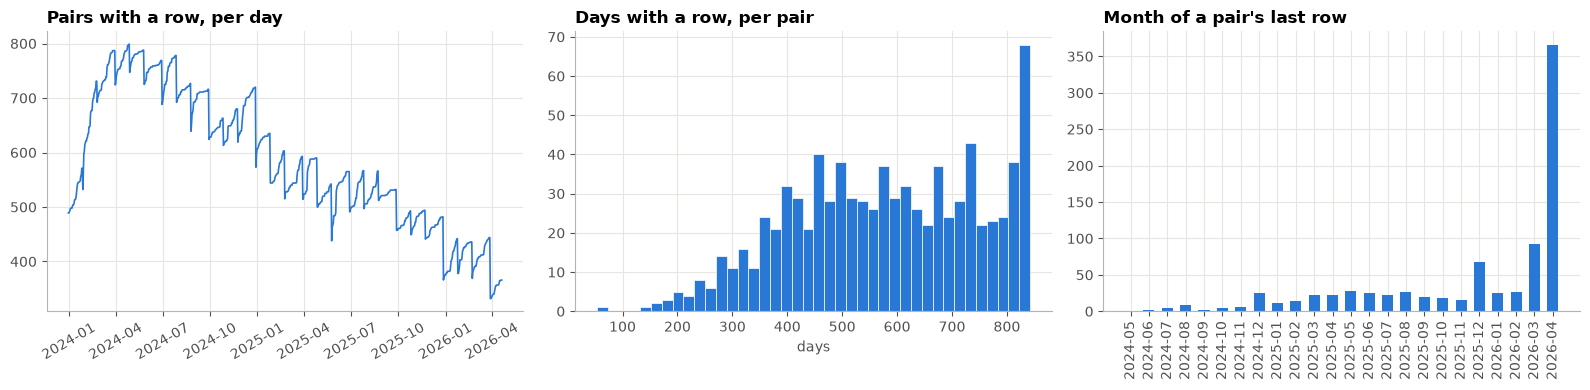

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rows_per_day = c_daily.groupby('date').size()
axes[0].plot(rows_per_day.index, rows_per_day.values, color=BLUE, linewidth=1.2)
axes[0].set_title('Pairs with a row, per day'); axes[0].tick_params(axis='x', rotation=30)
axes[1].hist(pair_info.rows, bins=40, **HIST)
axes[1].set_title('Days with a row, per pair'); axes[1].set_xlabel('days')
last_m = pair_info['last'].dt.to_period('M').value_counts().sort_index()
axes[2].bar(last_m.index.astype(str), last_m.values, color=BLUE, width=0.6)
axes[2].set_title("Month of a pair's last row"); axes[2].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

- The number of listed pairs falls steadily, and only 43% of pairs are still there on the last day.
- Inside a pair's lifetime there are gaps of weeks (median 31 days). They create the sawtooth in the left panel: gaps typically start in the last week of a month and end around mid-month.
- So a missing row most likely means *not listed / not carried that day*, not *zero sales*. When building a grid for forecasting, don't fill missing days with 0 blindly. Treat them as unknown, or fill only short gaps.

## C2. What the code columns mean
`is_return`, `sales_type` and `stock_status` are codes. Cross-tabulate them to work out what they mean.

In [11]:
display(pd.crosstab(c_daily.sales_type, c_daily.is_return, margins=True))
display(c_daily.groupby('is_return')['units'].describe())
display(pd.crosstab(c_daily.sales_type, c_daily.stock_status))

is_return,-1,0,1,All
sales_type,,,,
C,45713,0,0,45713
MD,0,65,0,65
MD_RETURN,0,0,7,7
PROMO,0,1291,0,1291
PROMO_RETURN,0,0,40,40
R,416663,27137,245,444045
R_RETURN,0,0,696,696
All,462376,28493,988,491857


,count,mean,std,min,25%,50%,75%,max
is_return,,,,,,,,
-1,462376.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
0,28493.0,1.179904,1.924372,1.0,1.0,1.0,1.0,292.0
1,988.0,-0.627530,0.903069,-3.0,-1.0,-1.0,0.0,10.0


stock_status,C,R
sales_type,,
C,45713,0
MD,65,0
MD_RETURN,7,0
PROMO,1291,0
PROMO_RETURN,40,0
R,1785,442260
R_RETURN,48,648


**Interpretation**
- `is_return = -1`: **no transaction that day**. Units are always 0, so this is a filler row that carries the stock and price state. `0` = sale, `1` = return.
- `sales_type`: `R` (regular), `C` (clearance), `PROMO`, `MD` (markdown), plus a `*_RETURN` variant of each. On filler rows it just repeats `stock_status`.
- `stock_status` (`C` / `R`) is the price status of the stock: clearance or regular. `PROMO` and `MD` sales only happen on clearance-status stock.

## C3. Stores and product hierarchy

In [12]:
print('Division values:', list(c_daily.division.unique()))
for child, parent in [('category', 'division'), ('subcategory', 'category'),
                      ('segment', 'subcategory'), ('article_id', 'segment')]:
    n_par = c_daily.groupby(child)[parent].nunique()
    print(f'{child:11s} ({c_daily[child].nunique():3d} values) -> {parent:11s}: '
          f'{(n_par > 1).sum()} with more than one parent')
multi = c_daily.groupby('subcategory')['category'].unique().loc[lambda s: s.str.len() > 1]
print('Subcategories under several categories:', {k: list(v) for k, v in multi.items()})

Division values: ['DIV-1']
category    ( 13 values) -> division   : 0 with more than one parent
subcategory ( 30 values) -> category   : 2 with more than one parent
segment     (171 values) -> subcategory: 1 with more than one parent
article_id  (338 values) -> segment    : 0 with more than one parent
Subcategories under several categories: {'SCAT-004': ['CAT-09', 'CAT-12'], 'SCAT-023': ['CAT-09', 'CAT-12']}


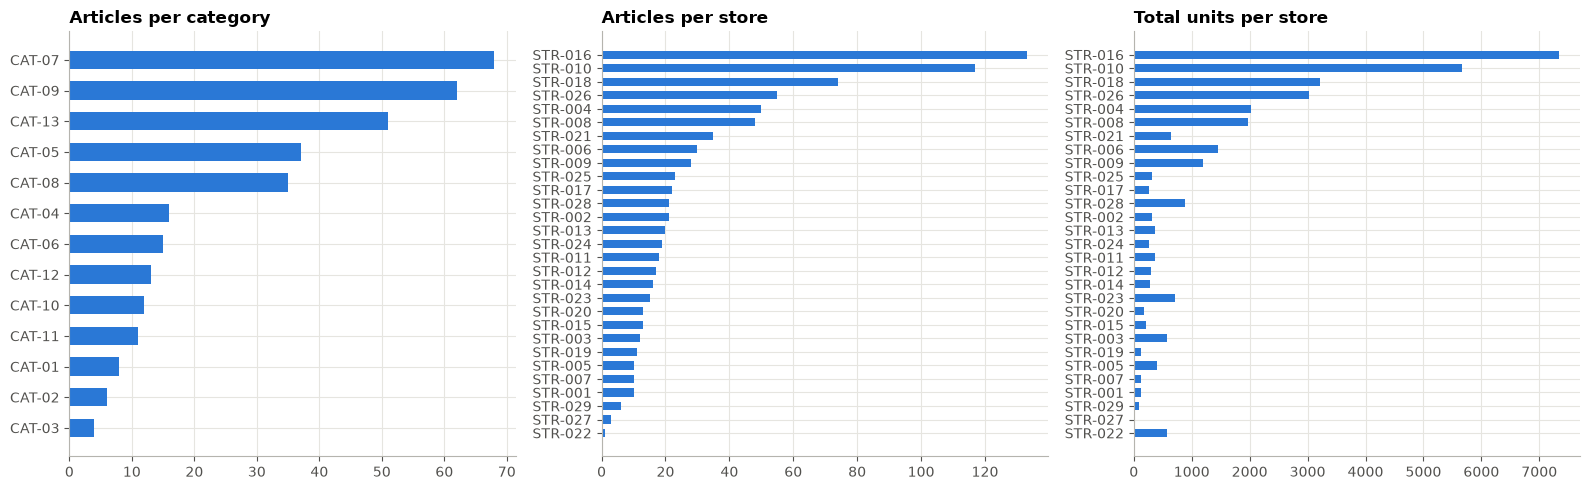

Two largest stores hold 29% of store×article pairs


In [13]:
store_sz = c_daily.groupby('store_id').agg(articles=('article_id', 'nunique'), units=('units', 'sum')).sort_values('articles')
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
cat_art = c_daily.groupby('category')['article_id'].nunique().sort_values()
axes[0].barh(cat_art.index, cat_art.values, color=BLUE, height=0.6); axes[0].set_title('Articles per category')
axes[1].barh(store_sz.index, store_sz.articles, color=BLUE, height=0.6); axes[1].set_title('Articles per store')
axes[2].barh(store_sz.index, store_sz.units, color=BLUE, height=0.6); axes[2].set_title('Total units per store')
plt.tight_layout(); plt.show()
print(f"Two largest stores hold {store_sz.articles.nlargest(2).sum() / store_sz.articles.sum():.0%} of store×article pairs")

## C4. Demand over time
Pairs leave the table over time (C1), so total units fall partly *because there are fewer pairs*. The second panel normalises by the number of listed pairs. Only complete weeks (7 days) are used.

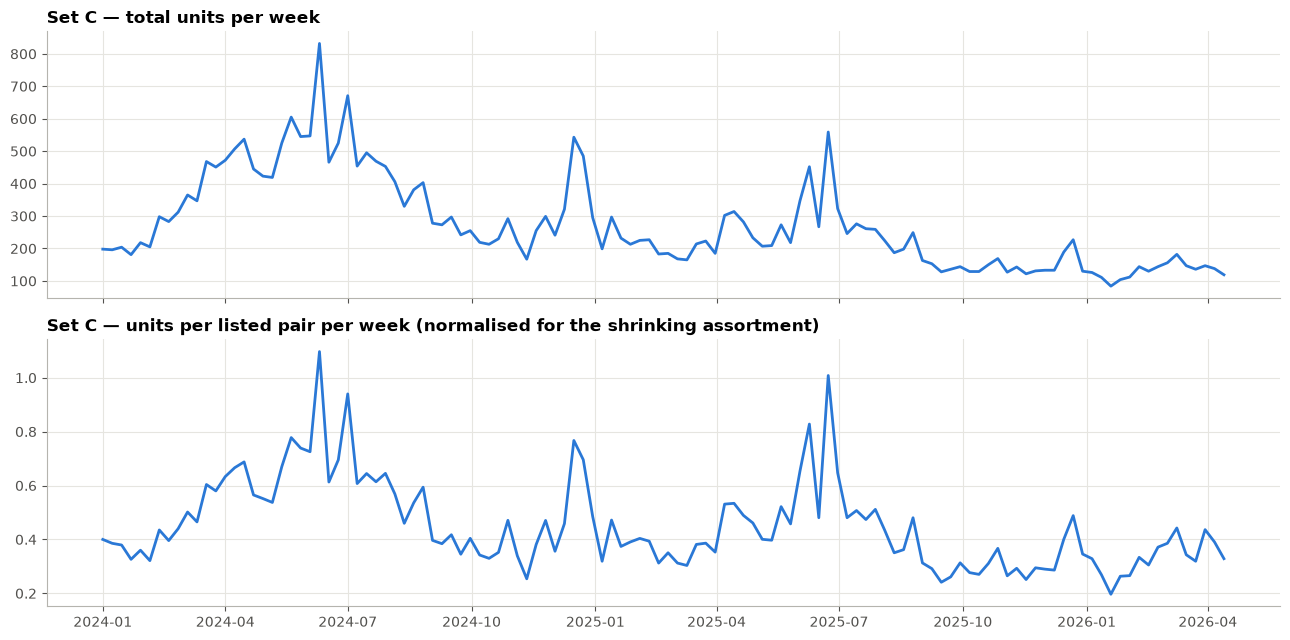

In [14]:
cw = (c_daily.assign(week=to_week(c_daily.date))
      .groupby('week').agg(units=('units', 'sum'), rows=('units', 'size'), days=('date', 'nunique')))
cw = cw[cw.days == 7]
cw['units_per_pair_week'] = cw.units / cw.rows * 7

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
axes[0].plot(cw.index, cw.units, color=BLUE); axes[0].set_title('Set C — total units per week')
axes[1].plot(cw.index, cw.units_per_pair_week, color=BLUE)
axes[1].set_title('Set C — units per listed pair per week (normalised for the shrinking assortment)')
plt.tight_layout(); plt.show()

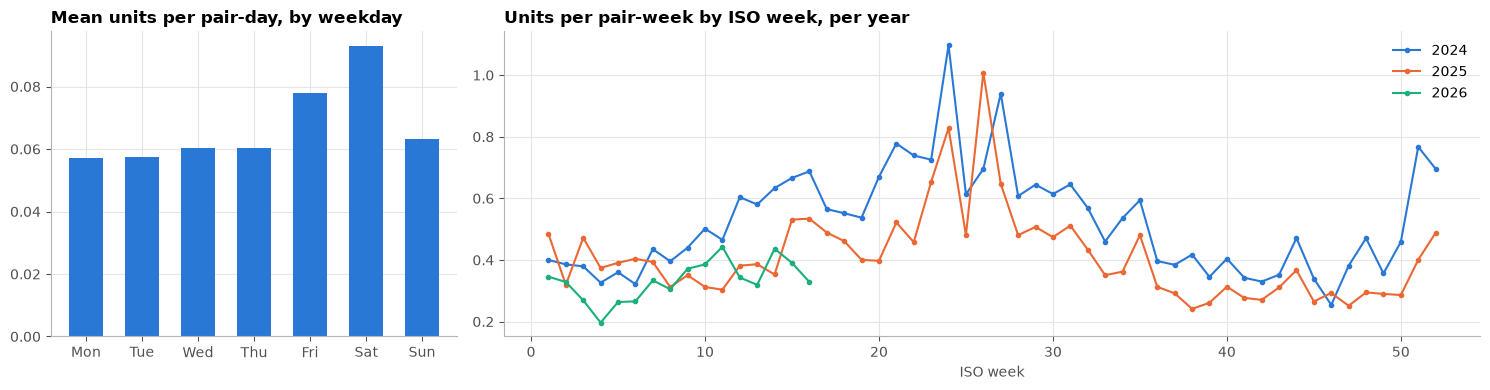

Weeks with the highest units per pair:


,units,units_per_pair_week
week,,
2024-06-10,832.0,1.097
2025-06-23,559.0,1.008
2024-07-01,671.0,0.940
2025-06-09,452.0,0.828
2024-05-20,605.0,0.778
2024-12-16,543.0,0.767
2024-05-27,545.0,0.739
2024-06-03,547.0,0.725


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2.4]})
wd = c_daily.groupby(c_daily.date.dt.day_of_week)['units'].mean()
axes[0].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], wd.values, color=BLUE, width=0.6)
axes[0].set_title('Mean units per pair-day, by weekday')

iso = cw.index.isocalendar()
yoy = cw.assign(year=iso.year.values, woy=iso.week.values).pivot_table(index='woy', columns='year', values='units_per_pair_week')
for i, y in enumerate(yoy.columns):
    axes[1].plot(yoy.index, yoy[y], color=CAT[i], label=str(y), marker='o', markersize=3, linewidth=1.5)
axes[1].set_title('Units per pair-week by ISO week, per year'); axes[1].set_xlabel('ISO week'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

print('Weeks with the highest units per pair:')
display(cw.nlargest(8, 'units_per_pair_week')[['units', 'units_per_pair_week']].round(3))

## C5. Demand distribution, sparsity and outliers

Rows with units = 0: 94.0% | > 0: 5.8% | < 0 (returns): 0.15%
Mean units per pair-day: median 0.060 (≈ one unit every 17 days)


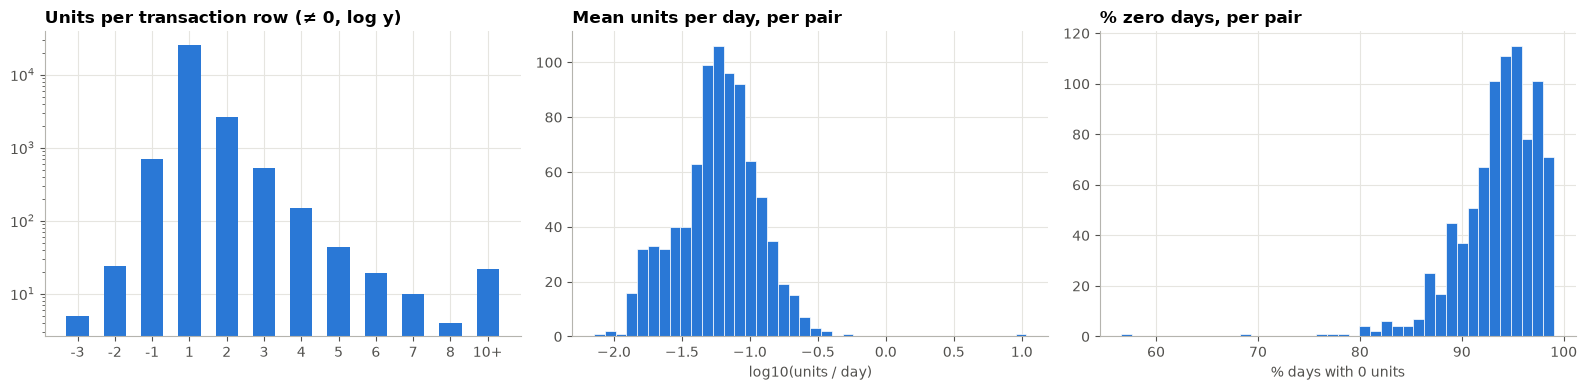

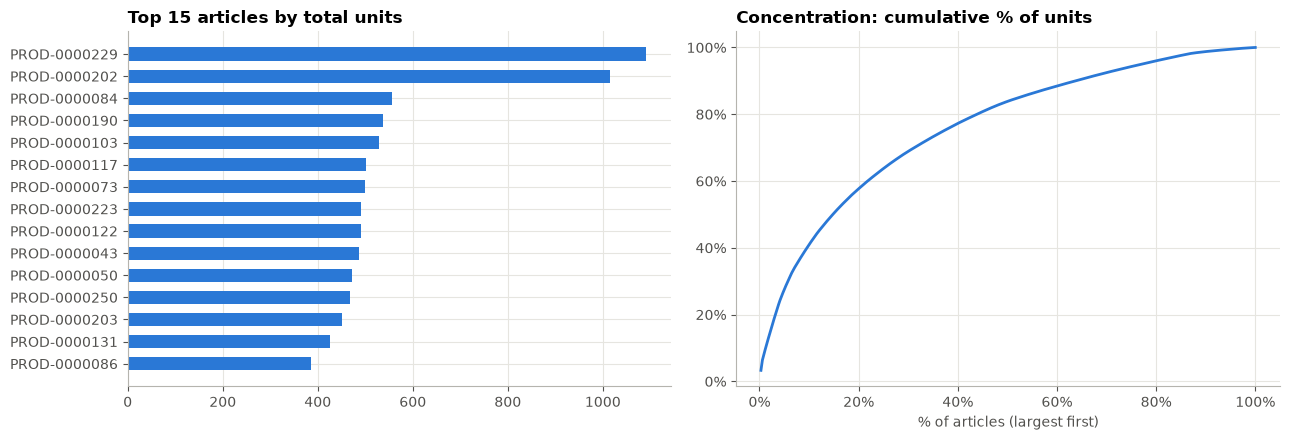

In [16]:
print(f"Rows with units = 0: {(c_daily.units == 0).mean():.1%} | > 0: {(c_daily.units > 0).mean():.1%} | < 0 (returns): {(c_daily.units < 0).mean():.2%}")
pair_mean = g['units'].mean()
pair_zero = g['units'].apply(lambda s: (s == 0).mean() * 100)
print(f'Mean units per pair-day: median {pair_mean.median():.3f} (≈ one unit every {1 / pair_mean.median():.0f} days)')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
u = c_daily.units[c_daily.units != 0]
vc = u.clip(upper=10).value_counts().sort_index()
axes[0].bar([str(int(i)) if i < 10 else '10+' for i in vc.index], vc.values, color=BLUE, width=0.6)
axes[0].set_yscale('log'); axes[0].set_title('Units per transaction row (≠ 0, log y)')
axes[1].hist(np.log10(pair_mean), bins=40, **HIST)
axes[1].set_title('Mean units per day, per pair'); axes[1].set_xlabel('log10(units / day)')
axes[2].hist(pair_zero, bins=40, **HIST)
axes[2].set_title('% zero days, per pair'); axes[2].set_xlabel('% days with 0 units')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_art = c_daily.groupby('article_id')['units'].sum().nlargest(15).sort_values()
axes[0].barh(top_art.index, top_art.values, color=BLUE, height=0.6); axes[0].set_title('Top 15 articles by total units')
art_tot = c_daily.groupby('article_id')['units'].sum().sort_values(ascending=False)
cum = art_tot.cumsum() / art_tot.sum()
axes[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=BLUE)
axes[1].set_title('Concentration: cumulative % of units'); axes[1].set_xlabel('% of articles (largest first)')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

In [17]:
# Outliers: the largest rows, and the article behind them
cols = ['date', 'store_id', 'article_id', 'units', 'sales_amount', 'unit_price', 'discount_pct', 'sales_type', 'on_hand']
top_rows = c_daily.nlargest(10, 'units')[cols]
display(top_rows)

art = top_rows.article_id.iloc[0]
a = c_daily[c_daily.article_id == art]
print(f'\n{art} by store (units, rows, price range):')
display(a.groupby('store_id').agg(units=('units', 'sum'), rows=('units', 'size'), max_units=('units', 'max'),
                                  price_min=('unit_price', 'min'), price_max=('unit_price', 'max'))
         .sort_values('units', ascending=False).head(8))
print(f"{art} = {a.units.sum() / c_daily.units.sum():.1%} of all Set C units")

,date,store_id,article_id,units,sales_amount,unit_price,discount_pct,sales_type,on_hand
413621,2025-06-27,STR-022,PROD-0000202,292.0,265.72,0.91,0.000000,R,40.0
70145,2025-01-24,STR-006,PROD-0000202,62.0,56.42,5.97,0.000000,R,1698.0
413611,2025-06-17,STR-022,PROD-0000202,54.0,48.98,0.91,0.003256,R,40.0
413597,2025-06-03,STR-022,PROD-0000202,42.0,32.22,0.91,0.156986,R,39.0
413600,2025-06-06,STR-022,PROD-0000202,40.0,33.20,0.91,0.087912,MD,39.0
413576,2025-04-07,STR-022,PROD-0000202,35.0,31.85,0.91,0.000000,R,4.0
464174,2025-01-15,STR-026,PROD-0000202,33.0,30.03,5.97,0.000000,R,577.0
413578,2025-04-09,STR-022,PROD-0000202,20.0,18.20,0.91,0.000000,R,4.0
413593,2025-04-24,STR-022,PROD-0000202,19.0,13.87,0.91,0.197802,R,4.0
324070,2025-01-17,STR-016,PROD-0000338,17.0,373.66,21.98,0.000000,R,365.0



PROD-0000202 by store (units, rows, price range):


,units,rows,max_units,price_min,price_max
store_id,,,,,
STR-022,574.0,53,292.0,0.91,0.910
STR-006,122.0,408,62.0,0.00,50.745
STR-026,118.0,422,33.0,0.00,5.970
STR-008,74.0,278,10.0,0.00,5.970
STR-003,70.0,327,6.0,0.00,5.970
STR-028,57.0,289,5.0,0.00,5.970


PROD-0000202 = 3.1% of all Set C units


## C6. Prices, discounts and sales types

In [18]:
tx = c_daily[c_daily.units != 0]          # transaction rows (sales + returns)
checks = {
    'sales_amount = units × unit_price − discount_amount': np.isclose(tx.sales_amount, tx.units * tx.unit_price - tx.discount_amount, atol=0.05),
    'sales_amount = units × unit_price':                    np.isclose(tx.sales_amount, tx.units * tx.unit_price, atol=0.05),
    'cogs = units × unit_cost':                             np.isclose(tx.cogs, tx.units * tx.unit_cost, atol=0.05),
    'discount_pct = discount / (sales + discount)':         np.isclose(tx.discount_pct, tx.discount_amount / (tx.sales_amount + tx.discount_amount), atol=0.01),
}
display(pd.DataFrame({'% of transaction rows': {k: round(100 * v.mean(), 1) for k, v in checks.items()}}))

by_type = tx.groupby('sales_type').agg(rows=('units', 'size'), units=('units', 'sum'), revenue=('sales_amount', 'sum'),
                                       discounted_rows_pct=('discount_amount', lambda s: round(100 * (s > 0).mean(), 1)),
                                       mean_discount_pct=('discount_pct', lambda s: round(100 * s.mean(), 1)))
display(by_type.sort_values('units', ascending=False))

n_price = c_daily.groupby('article_id')['unit_price'].nunique()
print(f'Articles with more than one unit_price over time: {(n_price > 1).mean():.0%} (max {n_price.max()} prices)')
print(f'Rows with unit_price = 0: {(c_daily.unit_price == 0).sum():,} | sales rows with units > 0 but sales_amount = 0: '
      f'{((c_daily.units > 0) & (c_daily.sales_amount == 0)).sum()}')

,% of transaction rows
sales_amount = units × unit_price − discount_amount,83.9
sales_amount = units × unit_price,68.6
cogs = units × unit_cost,97.7
discount_pct = discount / (sales + discount),99.5


,rows,units,revenue,discounted_rows_pct,mean_discount_pct
sales_type,,,,,
R,27330,31679.0,1091228.79,12.3,3.8
PROMO,1291,1691.0,23875.92,97.1,28.0
MD,65,116.0,1964.33,76.9,24.4
MD_RETURN,7,-7.0,-167.63,28.6,0.0
PROMO_RETURN,29,-29.0,-629.64,3.4,0.9
R_RETURN,567,-451.0,-23525.04,4.2,1.2


Articles with more than one unit_price over time: 91% (max 9 prices)
Rows with unit_price = 0: 8,141 | sales rows with units > 0 but sales_amount = 0: 103


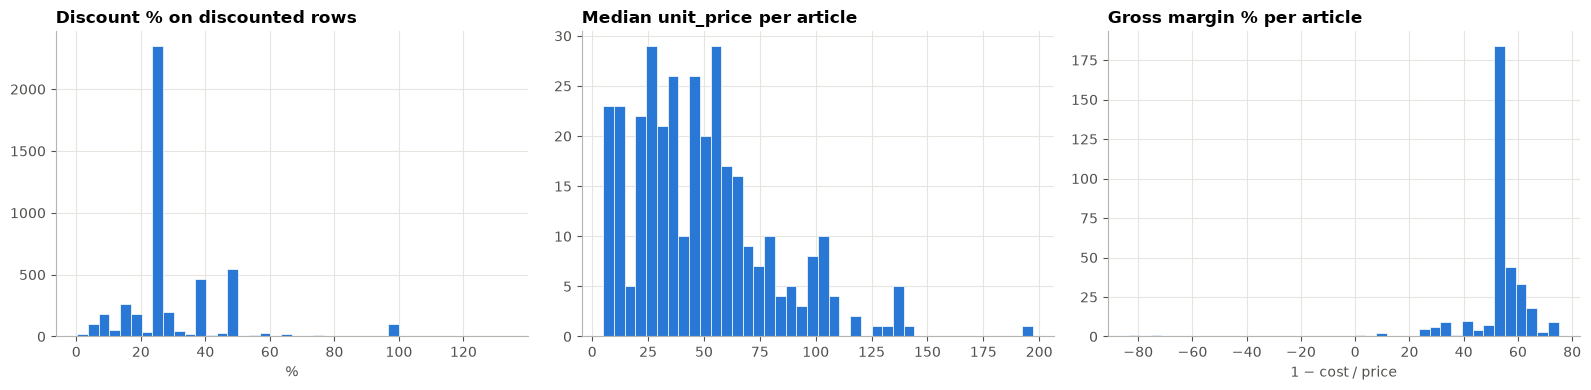

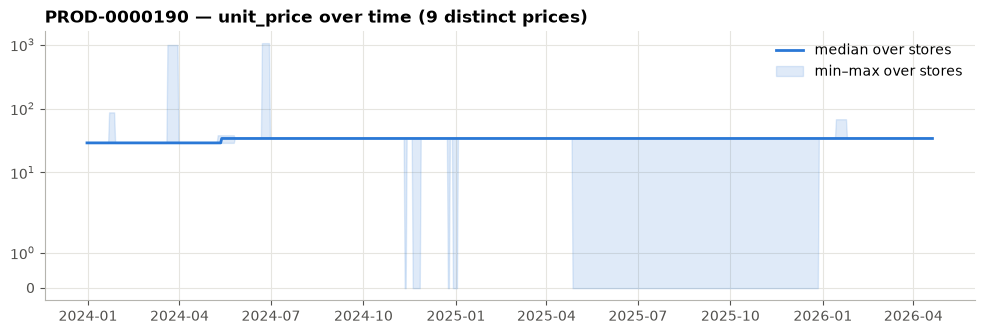

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
dp = tx.loc[tx.discount_pct > 0, 'discount_pct'] * 100
axes[0].hist(dp, bins=40, **HIST); axes[0].set_title('Discount % on discounted rows'); axes[0].set_xlabel('%')
art_price = c_daily.groupby('article_id')[['unit_price', 'unit_cost']].median()
axes[1].hist(art_price.unit_price, bins=40, **HIST); axes[1].set_title('Median unit_price per article')
margin = 100 * (1 - art_price.unit_cost / art_price.unit_price.replace(0, np.nan))
axes[2].hist(margin.dropna(), bins=40, **HIST); axes[2].set_title('Gross margin % per article'); axes[2].set_xlabel('1 − cost / price')
plt.tight_layout(); plt.show()

# Price history of the article with the most price changes
art = n_price.idxmax()
ph = c_daily[c_daily.article_id == art].groupby('date')['unit_price'].agg(['min', 'median', 'max'])
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(ph.index, ph['median'], color=BLUE, label='median over stores')
ax.fill_between(ph.index, ph['min'], ph['max'], color=BLUE, alpha=0.15, label='min–max over stores')
ax.set_yscale('symlog'); ax.set_title(f'{art} — unit_price over time ({n_price.max()} distinct prices)'); ax.legend(frameon=False)
plt.show()

## C7. Stock: `on_hand`, audit anomalies, recency, phasing-out

In [20]:
print(f'on_hand: median {c_daily.on_hand.median():.0f}, 90% {c_daily.on_hand.quantile(.9):.0f}, max {c_daily.on_hand.max():,.0f} | '
      f'= 0: {(c_daily.on_hand == 0).mean():.1%} | negative: {(c_daily.on_hand < 0).sum()}')
print('\nis_audit_anomaly vs on_hand == 0:')
display(pd.crosstab(c_daily.is_audit_anomaly, c_daily.on_hand == 0, rownames=['is_audit_anomaly'], colnames=['on_hand == 0']))

# Does on_hand move with sales? Compare consecutive days of the same pair
c_daily['oh_change'] = c_daily.groupby(PAIR)['on_hand'].diff()
consec = c_daily.groupby(PAIR)['date'].diff().dt.days.eq(1)
sd = c_daily[consec & (c_daily.units > 0)]
print(f'\nOn days with a sale (n={len(sd):,}): on_hand fell by exactly the units sold on {np.isclose(sd.oh_change, -sd.units).mean():.1%}, '
      f'stayed the same on {(sd.oh_change == 0).mean():.1%}, changed by another amount on the rest.')
cover = (g['on_hand'].median() / g['units'].mean()).replace(np.inf, np.nan)
print(f'Days of cover (median on_hand ÷ mean daily units), median over pairs: {cover.median():,.0f} days')

print(f"\nlatest_on_hand constant within every pair: {(g['latest_on_hand'].nunique() == 1).all()} "
      f"| equals the pair's last on_hand: {(g['on_hand'].last() == g['latest_on_hand'].first()).mean():.0%}")
print(f"days_since_sale    = date − last_sold_date:    {((c_daily.date - c_daily.last_sold_date).dt.days == c_daily.days_since_sale).mean():.1%} of rows")
print(f"days_since_receipt = date − last_receipt_date: {((c_daily.date - c_daily.last_receipt_date).dt.days == c_daily.days_since_receipt).mean():.1%} of rows "
      f"(last_receipt_date missing on {c_daily.last_receipt_date.isna().mean():.0%})")
print(f"is_phasing_out: {c_daily.is_phasing_out.mean():.0%} of rows; pairs that switch status at least once: {(g['is_phasing_out'].nunique() > 1).mean():.0%}")
po_rows = c_daily[c_daily.is_phasing_out]
print(f"  rows with is_phasing_out = True AND a sale: {(po_rows.units > 0).sum()} | smallest days_since_sale when True: {po_rows.days_since_sale.min():.0f}"
      f" | rows with days_since_sale >= that but flag False: {(c_daily.loc[~c_daily.is_phasing_out, 'days_since_sale'] >= po_rows.days_since_sale.min()).mean():.0%}")
print('  -> the flag is (partly) derived from recent sales: it is never set on a sale day, so using it as a same-day feature leaks the target.')

on_hand: median 134, 90% 588, max 10,885 | = 0: 3.7% | negative: 0

is_audit_anomaly vs on_hand == 0:


on_hand == 0,False,True
is_audit_anomaly,,
False,473728,8080
True,0,10049



On days with a sale (n=28,390): on_hand fell by exactly the units sold on 4.4%, stayed the same on 4.8%, changed by another amount on the rest.
Days of cover (median on_hand ÷ mean daily units), median over pairs: 2,195 days

latest_on_hand constant within every pair: True | equals the pair's last on_hand: 47%
days_since_sale    = date − last_sold_date:    98.9% of rows
days_since_receipt = date − last_receipt_date: 83.5% of rows (last_receipt_date missing on 16%)
is_phasing_out: 23% of rows; pairs that switch status at least once: 81%
  rows with is_phasing_out = True AND a sale: 0 | smallest days_since_sale when True: 31 | rows with days_since_sale >= that but flag False: 12%
  -> the flag is (partly) derived from recent sales: it is never set on a sale day, so using it as a same-day feature leaks the target.


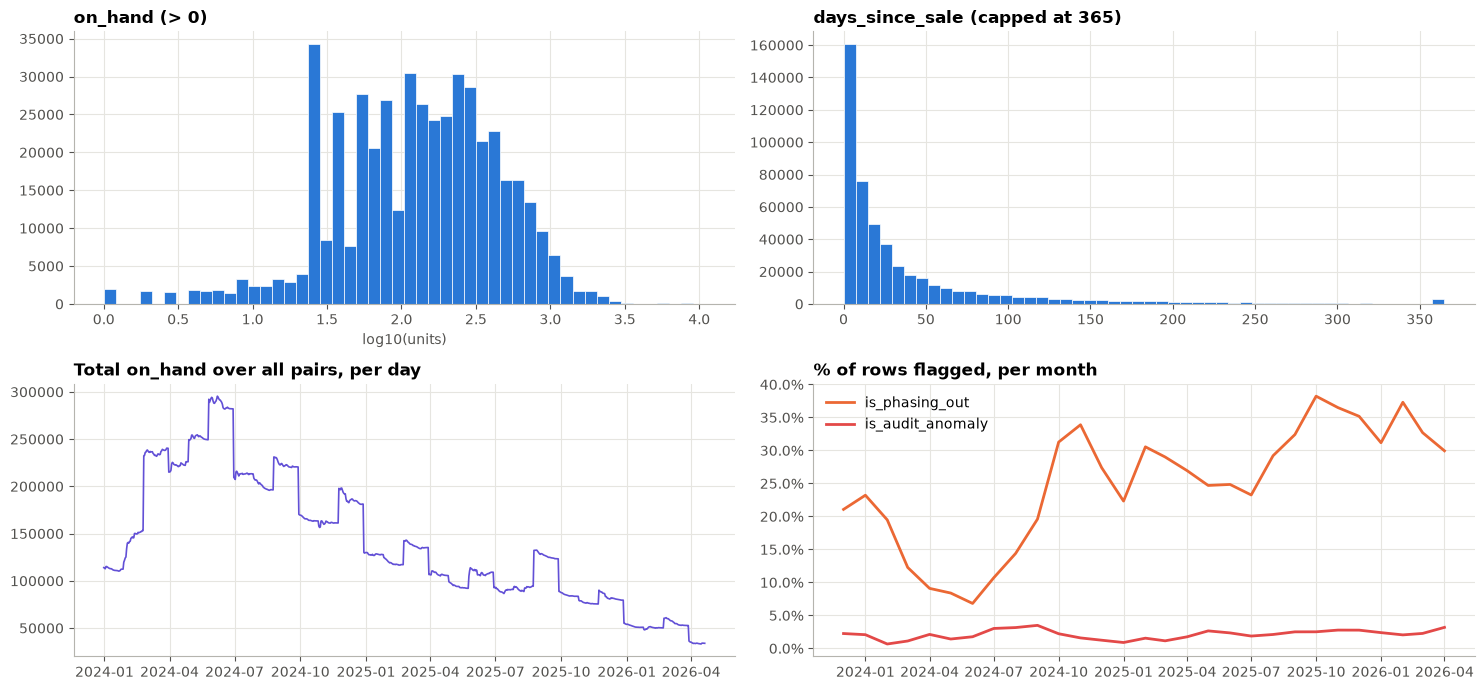

Mean units per pair-day by is_phasing_out: {False: 0.0877, True: -0.0004}


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
oh = c_daily.on_hand[c_daily.on_hand > 0]
axes[0, 0].hist(np.log10(oh), bins=50, **HIST); axes[0, 0].set_title('on_hand (> 0)'); axes[0, 0].set_xlabel('log10(units)')
axes[0, 1].hist(c_daily.days_since_sale.dropna().clip(upper=365), bins=50, **HIST)
axes[0, 1].set_title('days_since_sale (capped at 365)')
oh_day = c_daily.groupby('date')['on_hand'].sum()
axes[1, 0].plot(oh_day.index, oh_day.values, color=VIOLET, linewidth=1.2); axes[1, 0].set_title('Total on_hand over all pairs, per day')
po = c_daily.groupby(c_daily.date.dt.to_period('M'))[['is_phasing_out', 'is_audit_anomaly']].mean() * 100
axes[1, 1].plot(po.index.to_timestamp(), po.is_phasing_out, color=ORANGE, label='is_phasing_out')
axes[1, 1].plot(po.index.to_timestamp(), po.is_audit_anomaly, color=RED, label='is_audit_anomaly')
axes[1, 1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1, 1].set_title('% of rows flagged, per month'); axes[1, 1].legend(frameon=False)
plt.tight_layout(); plt.show()

# Do phasing-out pairs sell less?
print('Mean units per pair-day by is_phasing_out:', c_daily.groupby('is_phasing_out')['units'].mean().round(4).to_dict())

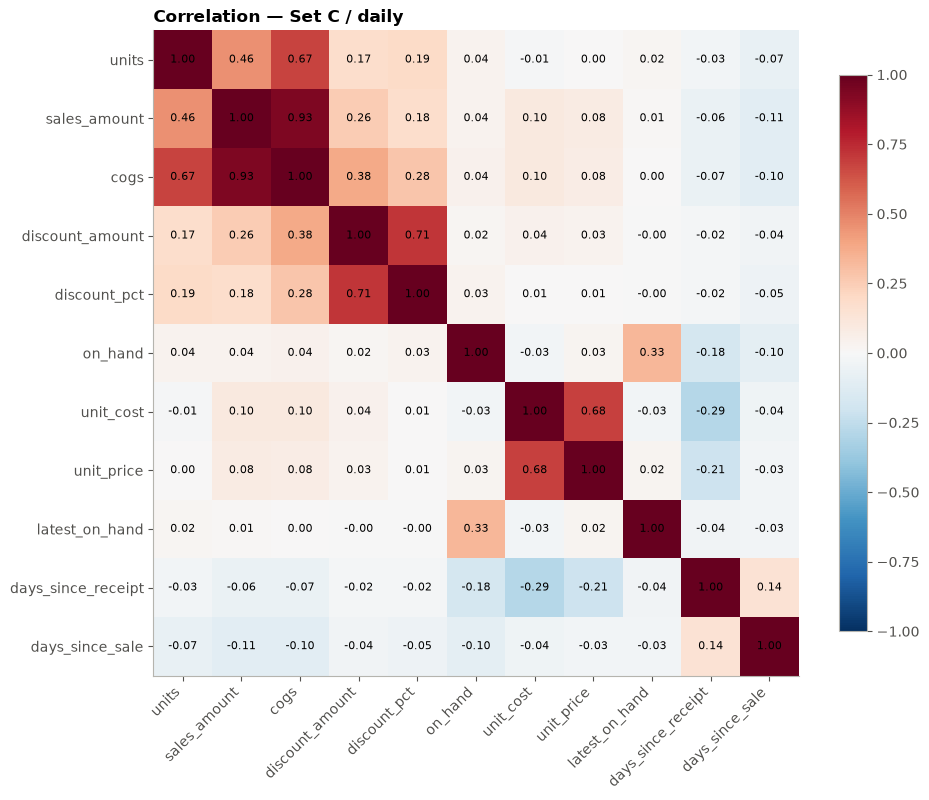

In [22]:
corr_heatmap(c_daily[['units', 'sales_amount', 'cogs', 'discount_amount', 'discount_pct', 'on_hand',
                      'unit_cost', 'unit_price', 'latest_on_hand', 'days_since_receipt', 'days_since_sale']],
             'Correlation — Set C / daily')

## C8. Set C — summary of findings

**Structure**
- One table, `daily`, with one row per store × article × day: 491,857 rows, 29 stores, 338 articles, 851 pairs, 842 days (2023-12-31 → 2026-04-20). No duplicate keys.
- Numbers come as `Decimal` and dates as `date` objects. Convert them before any analysis.
- Hierarchy: 1 division > 13 categories > 30 subcategories > 171 segments > 338 articles. It is almost a clean tree: two subcategories (SCAT-004, SCAT-023) sit under two categories.
- Stores are very unequal: the two largest (STR-016, STR-010) hold 29% of pairs, and the smallest has a single article.

**Coverage**
- Only 69% of the full pair × day grid exists. Listed pairs drop from ~800 to ~350. Gaps (median 31 days) usually start in the last week of a month and end mid-month.
- Missing rows ≠ zero sales. Only fill zeros inside listed periods.

**Code columns**
- `is_return`: −1 = no transaction (filler row, units always 0), 0 = sale, 1 = return.
- `sales_type`: R / C / PROMO / MD plus `*_RETURN`. On filler rows it equals `stock_status` (R = regular, C = clearance). PROMO and MD sales only happen on clearance-status stock.

**Demand**
- 94% zero rows, 0.15% returns. Median pair: 0.06 units/day. Sales per transaction row are mostly 1 unit.
- Main peak in **June** (KW24–26, ~2–2.5× a normal week in both 2024 and 2025), a smaller one before Christmas (KW51), and spring above autumn. Fri/Sat are ~1.3–1.6× Mon–Thu.
- Demand per listed pair is lower in 2025/26 than in 2024 for most weeks.
- Outliers: **PROD-0000202** causes the 9 largest rows. In STR-022 it is listed for only 53 days at price 0.91 (5.97 elsewhere) and sells 574 units, including 292 on 2025-06-27. It looks like a bulk sale or a pack-size error. Cap it or exclude it before training.

**Prices and discounts**
- `cogs = units × unit_cost` holds on 98% of transaction rows and `discount_pct` is consistent (99.5%). `sales_amount = units × unit_price − discount` only holds on 84%.
- 91% of articles have more than one `unit_price` over time. There are price glitches: 8,141 rows at price 0, and short spikes to ~1,000 for a ~30 article.
- PROMO rows have ~28% discount and MD ~24%. 12% of regular sales also carry a discount.

**Stock and flags**
- `on_hand` does **not** track sales: on sale days it fell by the units sold only 4% of the time. The median pair holds ~2,200 days of demand. It probably measures something other than store shelf stock (e.g. a wider stock pool or a lagged snapshot), so it is weak as a stock-out signal.
- `is_audit_anomaly` ⊂ `on_hand = 0`: about half of the zero-stock rows are flagged.
- `latest_on_hand` is constant per pair (a single "current" value, even negative), so it is useless as a time feature.
- `days_since_sale` matches `date − last_sold_date` on 99% of rows. `days_since_receipt` is missing on 16% of rows.
- `is_phasing_out` covers 23% of rows (rising over time) and is **never set on a sale day**. It only appears after ≥ 31 days without a sale. That is target leakage if used as a same-day feature.

# Part II — Set D (sales lines + stock intervals)
## D1. Sales: grain and coverage

In [23]:
all_days = pd.date_range(d_sales.date.min(), D_END)
print(f'Date range: {d_sales.date.min().date()} → {D_END.date()} ({d_sales.date.nunique()} of {len(all_days)} days)')
print('Days with no sales at all:', [d.date() for d in all_days.difference(d_sales.date.unique())])
print('Duplicate (date, store, article, sales_type, is_return) rows:',
      d_sales.duplicated(['date', *PAIR, 'sales_type', 'is_return']).sum())
for name, df in set_d.items():
    print(f'Constant columns in {name}:', [c for c in df.columns if df[c].nunique(dropna=False) == 1])

dg = d_sales.groupby(PAIR)
print(f'\nStores: {d_sales.store_id.nunique()} | articles: {d_sales.article_id.nunique()} | suppliers: {d_sales.supplier_id.nunique()} '
      f'| store×article pairs with a sale: {dg.ngroups:,}')
days_per_pair = dg['date'].nunique()
print(f'Days with a sale per pair: median {days_per_pair.median():.0f}, mean {days_per_pair.mean():.1f}; '
      f'pairs that sold on one day only: {(days_per_pair == 1).mean():.0%}')

Date range: 2025-06-01 → 2026-04-24 (326 of 328 days)
Days with no sales at all: [datetime.date(2025, 11, 27), datetime.date(2025, 12, 25)]
Duplicate (date, store, article, sales_type, is_return) rows: 0
Constant columns in sales: ['return_reason', 'sales_channel']
Constant columns in stock: ['store_type', 'sales_channel']

Stores: 40 | articles: 2326 | suppliers: 30 | store×article pairs with a sale: 50,447
Days with a sale per pair: median 2, mean 2.5; pairs that sold on one day only: 40%


Unlike Set C, `sales` only contains days **with** a transaction; zero days are not stored. A store × article pair sells on average on only ~2–3 days in 11 months, so at the store × article × day level the data is almost all zeros (see D5).

## D2. Sales types and returns

In [24]:
display(pd.crosstab(d_sales.sales_type, d_sales.is_return, margins=True))
ret = d_sales.groupby('sales_type').apply(lambda x: pd.Series({
    'sold_units': x.loc[x.is_return == 0, 'units'].sum(),
    'returned_units': -x.loc[x.is_return == 1, 'units'].sum()}), include_groups=False)
ret['return_rate_%'] = (100 * ret.returned_units / ret.sold_units).round(1)
display(ret.sort_values('sold_units', ascending=False))
print('return_reason filled on', d_sales.return_reason.notna().sum(), 'rows')
print(f"units ≥ transactions on {(d_sales.units.abs() >= d_sales.transactions).mean():.2%} of rows; "
      f"rows with >1 transaction: {(d_sales.transactions > 1).mean():.1%}")
print('Units per row:', d_sales.units.value_counts().sort_index().to_dict())

is_return,0,1,All
sales_type,,,
CLEARANCE,1328,25,1353
FULL_PRICE,87996,5933,93929
MARKDOWN_TIER_1,4143,241,4384
MARKDOWN_TIER_2,2340,94,2434
PROMO,22453,1198,23651
All,118260,7491,125751


,sold_units,returned_units,return_rate_%
sales_type,,,
FULL_PRICE,93235.0,5976.0,6.4
PROMO,23053.0,1208.0,5.2
MARKDOWN_TIER_1,4268.0,243.0,5.7
MARKDOWN_TIER_2,2461.0,94.0,3.8
CLEARANCE,1525.0,26.0,1.7


return_reason filled on 0 rows
units ≥ transactions on 100.00% of rows; rows with >1 transaction: 3.0%
Units per row: {-3.0: 2, -2.0: 52, -1.0: 7437, 0.0: 2, 1.0: 113712, 2.0: 3664, 3.0: 491, 4.0: 200, 5.0: 80, 6.0: 40, 7.0: 29, 8.0: 21, 9.0: 7, 10.0: 7, 11.0: 3, 12.0: 1, 13.0: 2, 14.0: 1}


## D3. Product hierarchy, suppliers and stores

category    (  27 values) -> division   : 0 with more than one parent
subcategory (  51 values) -> category   : 0 with more than one parent
segment     ( 600 values) -> subcategory: 0 with more than one parent
article_id  (2326 values) -> segment    : 0 with more than one parent
article_id  (2326 values) -> supplier_id: 0 with more than one parent


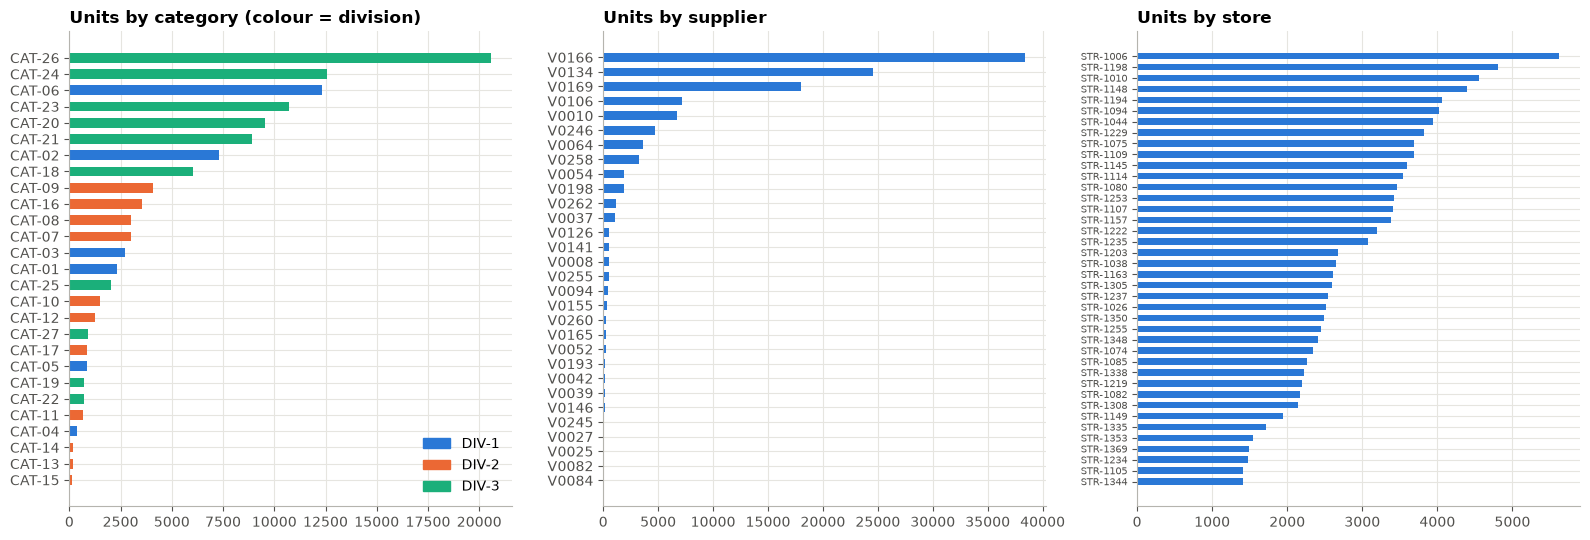

Top 3 suppliers = 69% of units | largest store / smallest store = 4.0x


In [25]:
for child, parent in [('category', 'division'), ('subcategory', 'category'), ('segment', 'subcategory'),
                      ('article_id', 'segment'), ('article_id', 'supplier_id')]:
    n_par = d_sales.groupby(child)[parent].nunique()
    print(f'{child:11s} ({d_sales[child].nunique():4d} values) -> {parent:11s}: {(n_par > 1).sum()} with more than one parent')

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
cat_u = d_sales.groupby(['division', 'category'])['units'].sum().reset_index().sort_values('units')
div_col = {d: CAT[i] for i, d in enumerate(sorted(d_sales.division.unique()))}
axes[0].barh(cat_u.category, cat_u.units, color=cat_u.division.map(div_col), height=0.6)
axes[0].set_title('Units by category (colour = division)')
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=c, label=d) for d, c in div_col.items()], frameon=False)
sup = d_sales.groupby('supplier_id')['units'].sum().sort_values()
axes[1].barh(sup.index, sup.values, color=BLUE, height=0.6); axes[1].set_title('Units by supplier')
st_u = d_sales.groupby('store_id')['units'].sum().sort_values()
axes[2].barh(st_u.index, st_u.values, color=BLUE, height=0.6); axes[2].set_title('Units by store'); axes[2].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()
print(f'Top 3 suppliers = {sup.nlargest(3).sum() / sup.sum():.0%} of units | largest store / smallest store = {st_u.max() / st_u.min():.1f}x')

## D4. Demand over time

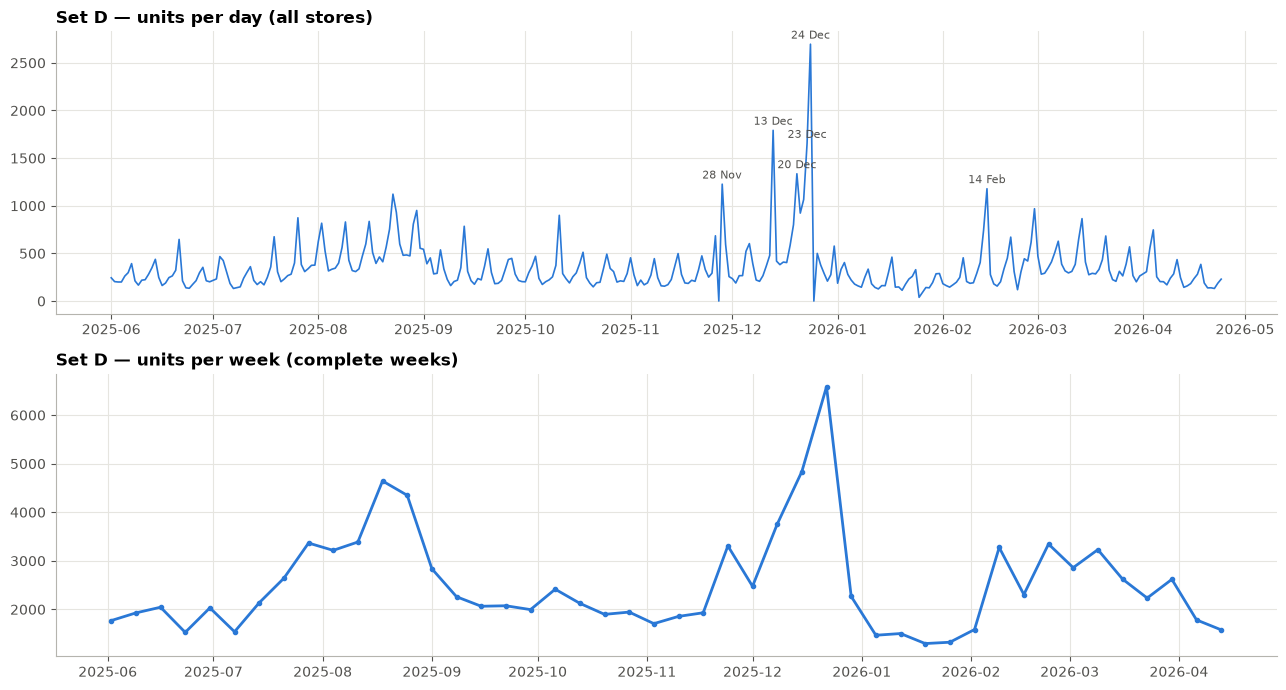

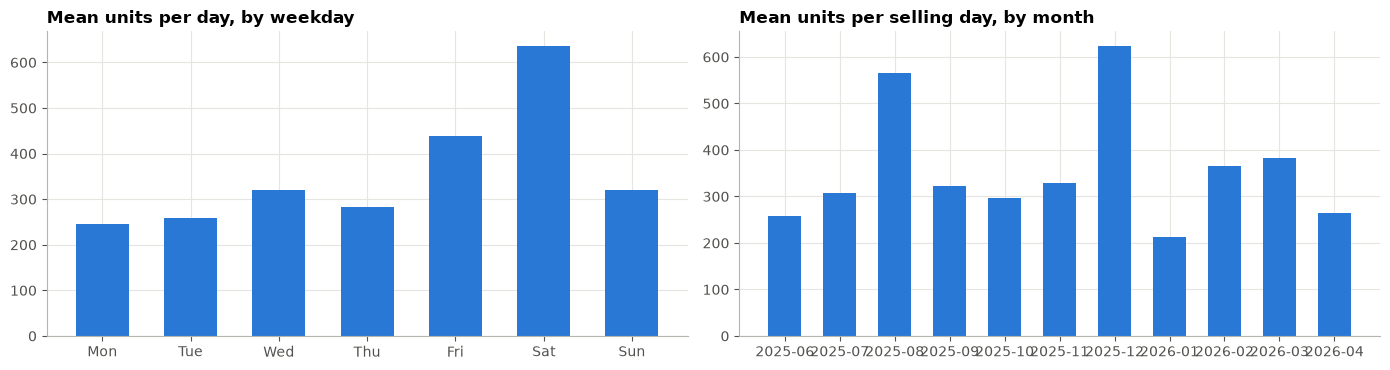

Top days:


,units,weekday
2025-12-24,2696.0,Wednesday
2025-12-13,1792.0,Saturday
2025-12-23,1654.0,Tuesday
2025-12-20,1336.0,Saturday
2025-11-28,1227.0,Friday
2026-02-14,1179.0,Saturday
2025-08-23,1122.0,Saturday
2025-12-22,1066.0,Monday
2026-02-28,969.0,Saturday
2025-08-30,951.0,Saturday


In [26]:
dd = d_sales.groupby('date')['units'].sum().reindex(all_days, fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(dd.index, dd.values, color=BLUE, linewidth=1.2)
for day, v in dd.nlargest(6).items():
    axes[0].annotate(day.strftime('%d %b'), (day, v), textcoords='offset points', xytext=(0, 4), ha='center', fontsize=8, color='#52514e')
axes[0].set_title('Set D — units per day (all stores)')
dw = d_sales.assign(week=to_week(d_sales.date)).groupby('week')['units'].sum()
axes[1].plot(dw.index[1:-1], dw.values[1:-1], color=BLUE, marker='o', markersize=3)   # drop partial first/last week
axes[1].set_title('Set D — units per week (complete weeks)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
wd = dd.groupby(dd.index.day_of_week).mean()
axes[0].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], wd.values, color=BLUE, width=0.6)
axes[0].set_title('Mean units per day, by weekday')
mo = d_sales.groupby(d_sales.date.dt.to_period('M')).agg(units=('units', 'sum'), days=('date', 'nunique'))
axes[1].bar(mo.index.astype(str), mo.units / mo.days, color=BLUE, width=0.6)
axes[1].set_title('Mean units per selling day, by month')
plt.tight_layout(); plt.show()
print('Top days:'); display(dd.nlargest(10).to_frame('units').assign(weekday=lambda x: x.index.day_name()))

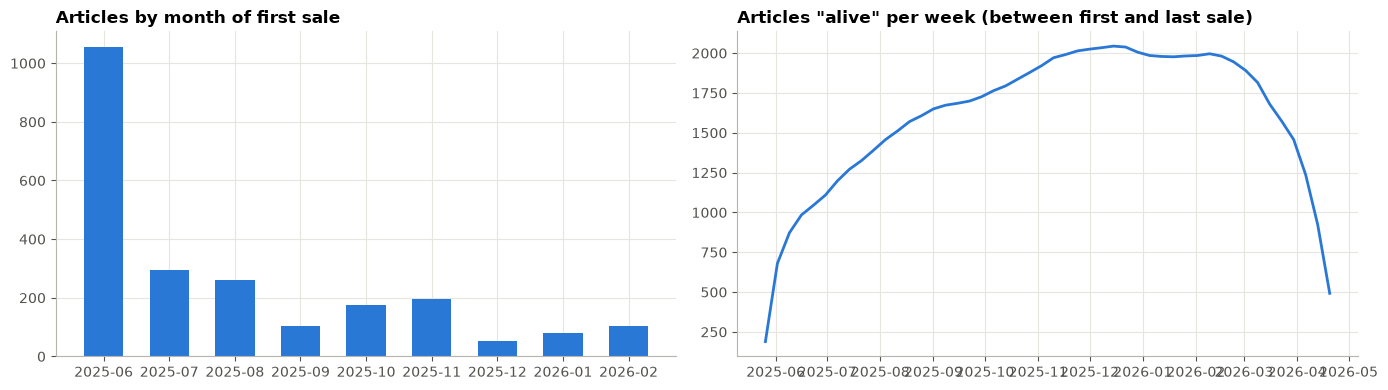

Articles first sold after the first month: 55% | no sale in the last 8 weeks: 17%


In [27]:
# Article lifecycle: when does each article first / last sell?
life = d_sales.groupby('article_id').agg(first=('date', 'min'), last=('date', 'max'), units=('units', 'sum'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fm = life['first'].dt.to_period('M').value_counts().sort_index()
axes[0].bar(fm.index.astype(str), fm.values, color=BLUE, width=0.6); axes[0].set_title("Articles by month of first sale")
weeks = pd.date_range(to_week(pd.Series([d_sales.date.min()]))[0], D_END, freq='W-MON')
alive = pd.Series([((life['first'] <= w + pd.Timedelta(days=6)) & (life['last'] >= w)).sum() for w in weeks], index=weeks)
axes[1].plot(alive.index, alive.values, color=BLUE); axes[1].set_title('Articles "alive" per week (between first and last sale)')
plt.tight_layout(); plt.show()
print(f"Articles first sold after the first month: {(life['first'] >= '2025-07-01').mean():.0%} | "
      f"no sale in the last 8 weeks: {(life['last'] < D_END - pd.Timedelta(weeks=8)).mean():.0%}")

## D5. Sparsity: at which level is Set D forecastable?
Share of periods with a sale, counted from each series' first sale to the end of the data, at different aggregation levels.

In [28]:
def density(df, keys, freq):
    per = df.assign(p=df.date.dt.to_period(freq)).groupby([*keys, 'p'])['units'].sum()
    per = per[per > 0].reset_index()
    gg = per.groupby(keys)
    span = (D_END.to_period(freq) - gg.p.min()).apply(lambda x: x.n) + 1
    return pd.Series({'series': gg.ngroups, 'cells_with_sale_%': round(100 * gg.size().sum() / span.sum(), 1),
                      'median_periods_with_sale': gg.size().median(),
                      'series_with_≤2_sales_%': round(100 * (gg.size() <= 2).mean(), 1)})

levels = {
    'store × article × day':  (PAIR, 'D'),
    'store × article × week': (PAIR, 'W-SUN'),
    'article × week (chain)': (['article_id'], 'W-SUN'),
    'store × segment × week': (['store_id', 'segment'], 'W-SUN'),
    'store × category × week': (['store_id', 'category'], 'W-SUN'),
}
display(pd.DataFrame({name: density(d_sales, k, f) for name, (k, f) in levels.items()}).T)

,series,cells_with_sale_%,median_periods_with_sale,series_with_≤2_sales_%
store × article × day,50075.0,1.2,2.0,72.0
store × article × week,49860.0,7.7,2.0,75.1
article × week (chain),2326.0,50.0,17.0,0.0
store × segment × week,13655.0,17.7,5.0,26.5
store × category × week,857.0,66.0,30.0,6.4


## D6. Prices and margin by sales type

,units,revenue,median_price,median_margin_pct,units_%,revenue_%
sales_type,,,,,,
FULL_PRICE,93233.0,9528191.52,100.00,49.42,74.9,85.0
PROMO,23049.0,1396945.26,69.99,29.93,18.5,12.5
MARKDOWN_TIER_1,4267.0,191442.86,49.99,13.82,3.4,1.7
MARKDOWN_TIER_2,2461.0,81334.12,39.99,-10.42,2.0,0.7
CLEARANCE,1525.0,17767.50,9.99,-54.15,1.2,0.2


Rows with sales_amount ≤ 0 or units = 0 (excluded above): 9


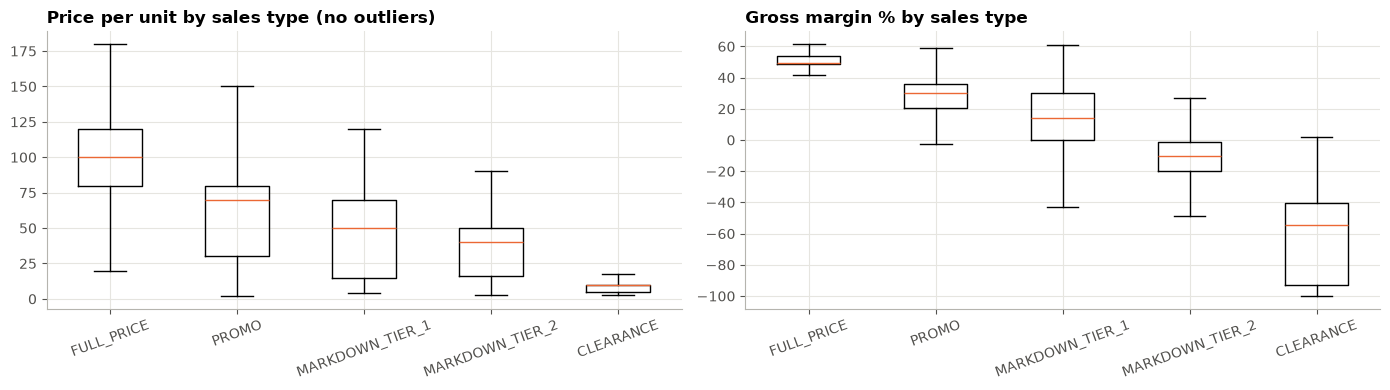

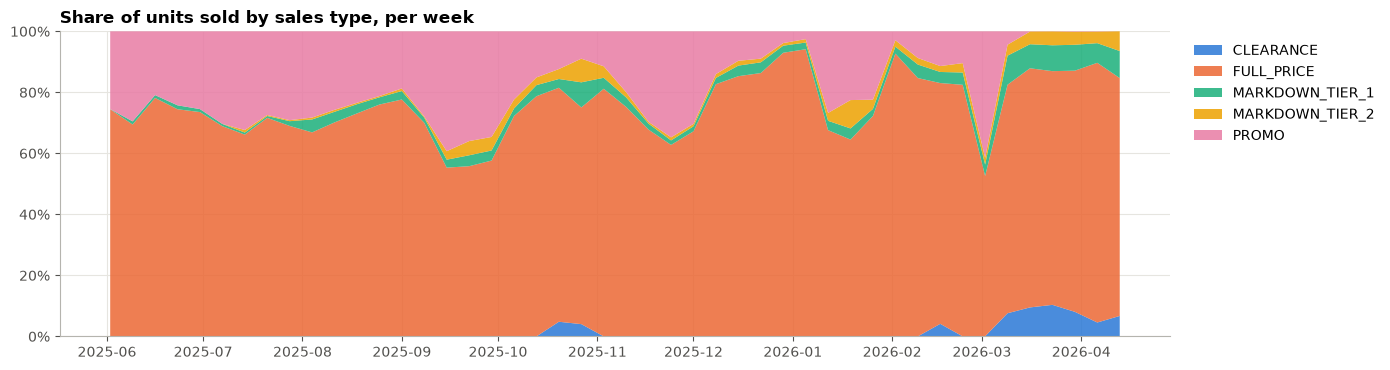

In [29]:
sold = d_sales[(d_sales.is_return == 0) & (d_sales.units > 0) & (d_sales.sales_amount > 0)].copy()
sold['unit_price'] = sold.sales_amount / sold.units
sold['margin_%'] = 100 * (1 - sold.cogs / sold.sales_amount)
pt = sold.groupby('sales_type').agg(units=('units', 'sum'), revenue=('sales_amount', 'sum'),
                                    median_price=('unit_price', 'median'), median_margin_pct=('margin_%', 'median'))
pt['units_%'] = (100 * pt.units / pt.units.sum()).round(1)
pt['revenue_%'] = (100 * pt.revenue / pt.revenue.sum()).round(1)
display(pt.sort_values('units', ascending=False).round(2))
print(f'Rows with sales_amount ≤ 0 or units = 0 (excluded above): {len(d_sales[d_sales.is_return == 0]) - len(sold)}')

order = pt.sort_values('median_price', ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot([sold.loc[sold.sales_type == t, 'unit_price'] for t in order], tick_labels=order, showfliers=False)
axes[0].set_title('Price per unit by sales type (no outliers)'); axes[0].tick_params(axis='x', rotation=20)
axes[1].boxplot([sold.loc[sold.sales_type == t, 'margin_%'].clip(-100, 100) for t in order], tick_labels=order, showfliers=False)
axes[1].set_title('Gross margin % by sales type'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

# How the sales-type mix changes over time
mix = sold.groupby([to_week(sold.date), 'sales_type'])['units'].sum().unstack(fill_value=0)
mix = mix.div(mix.sum(axis=1), axis=0).iloc[1:-1] * 100
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.stackplot(mix.index, mix.T.values, labels=mix.columns, colors=CAT[:mix.shape[1]], alpha=0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100)
ax.set_title('Share of units sold by sales type, per week'); ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## D7. Stock intervals
Each row says: *from `start_date` to `end_date`, this store × article had `on_hand` units at `unit_price`*. A new row starts whenever the stock or price status changes.

In [30]:
kg = d_stock.groupby(PAIR)
d_stock['days'] = (d_stock.end_date - d_stock.start_date).dt.days + 1
print(f'{len(d_stock):,} intervals for {kg.ngroups:,} store×article pairs ({len(d_stock) / kg.ngroups:.1f} per pair)')
print(f"start_date: {d_stock.start_date.min().date()} → {d_stock.start_date.max().date()} | open intervals (9999-12-31): "
      f"{d_stock.is_open.sum():,} = one per pair still in the data at the end: {d_stock[d_stock.is_open].groupby(PAIR).ngroups:,}")
print('Interval length (days, closed intervals):', d_stock.loc[~d_stock.is_open, 'days'].describe()[['50%', 'mean', 'max']].round(1).to_dict())
print('Duplicate (store, article, start_date):', d_stock.duplicated([*PAIR, 'start_date']).sum())

k = d_stock.sort_values([*PAIR, 'start_date'])
gap = (k.start_date - k.groupby(PAIR).end_date.shift()).dt.days
print(f'Next interval starts the day after the previous ends: {(gap == 1).sum() / gap.notna().sum():.0%} '
      f'(otherwise a gap, median {gap[gap > 1].median():.0f} days; overlaps: {(gap < 1).sum()})')

print(f'\non_hand: = 0 on {(d_stock.on_hand == 0).mean():.1%} | negative on {(d_stock.on_hand < 0).sum()} rows | max {d_stock.on_hand.max()}')
print('unit_price = 0 exactly when on_hand = 0?',
      ((d_stock.unit_price == 0) == (d_stock.on_hand == 0)).all())
print(f"stock_value_at_price = on_hand × unit_price: {np.isclose(d_stock.stock_value_at_price, d_stock.on_hand * d_stock.unit_price).mean():.1%} | "
      f"stock_value_at_cost = on_hand × unit_cost: {np.isclose(d_stock.stock_value_at_cost, d_stock.on_hand * d_stock.unit_cost).mean():.1%}")
print(f'Negative unit_cost rows: {(d_stock.unit_cost < 0).sum()}')
display(d_stock.groupby('stock_status').agg(intervals=('on_hand', 'size'), median_price=('unit_price', 'median'),
                                            mean_on_hand=('on_hand', 'mean')).sort_values('intervals', ascending=False))

284,755 intervals for 60,968 store×article pairs (4.7 per pair)
start_date: 2025-06-01 → 2026-04-24 | open intervals (9999-12-31): 22,701 = one per pair still in the data at the end: 22,701
Interval length (days, closed intervals): {'50%': 8.0, 'mean': 28.8, 'max': 317.0}
Duplicate (store, article, start_date): 0
Next interval starts the day after the previous ends: 96% (otherwise a gap, median 20 days; overlaps: 0)

on_hand: = 0 on 4.9% | negative on 1380 rows | max 56
unit_price = 0 exactly when on_hand = 0? True
stock_value_at_price = on_hand × unit_price: 100.0% | stock_value_at_cost = on_hand × unit_cost: 95.3%
Negative unit_cost rows: 25


,intervals,median_price,mean_on_hand
stock_status,,,
FULL_PRICE,261899,105.00,2.305729
MARKDOWN_TIER_1,12091,34.99,1.976677
MARKDOWN_TIER_2,6937,24.99,2.225746
CLEARANCE,3798,9.99,2.672196
PROMO,30,45.00,1.666667


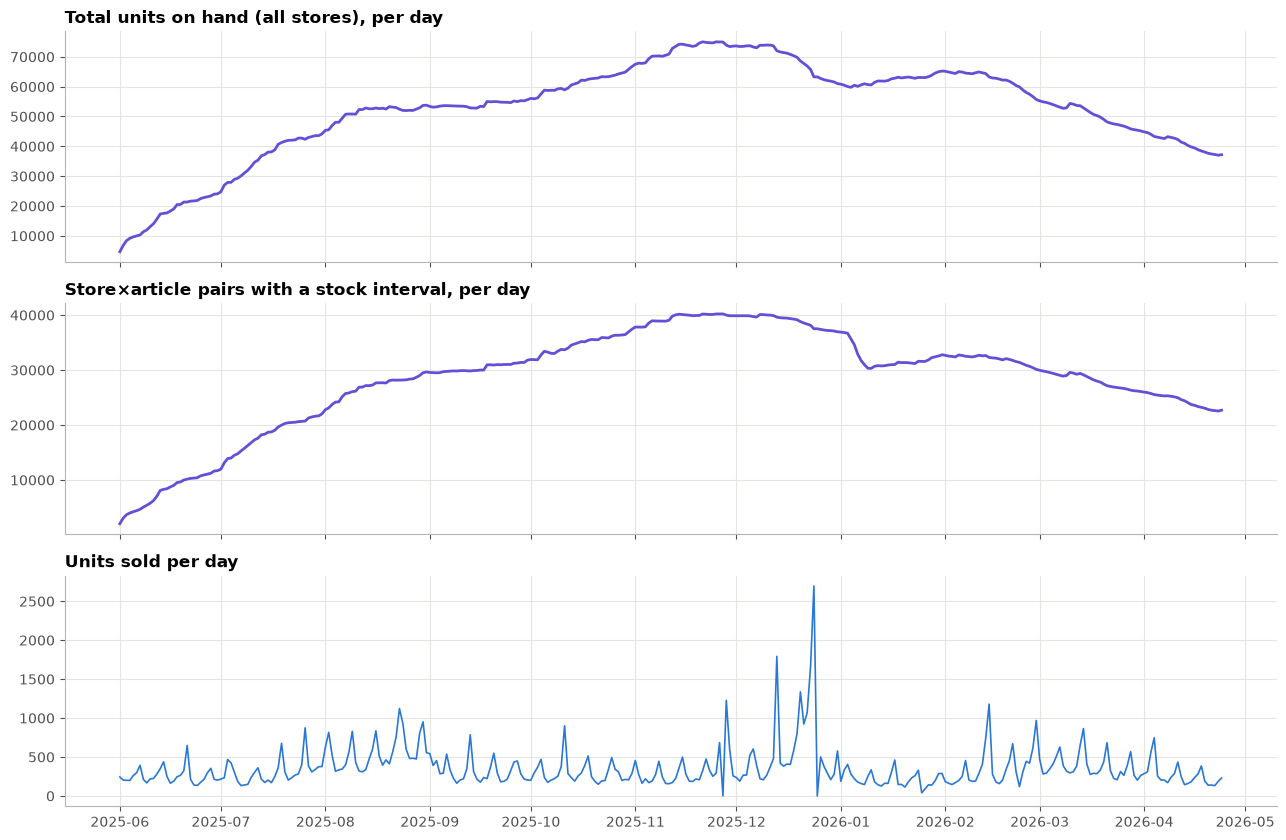

In [31]:
# Chain-wide stock per day, rebuilt from the intervals (add on start, subtract the day after end)
days = pd.date_range(d_stock.start_date.min(), D_END)
add = d_stock.groupby('start_date')['on_hand'].sum()
sub = d_stock.groupby(d_stock.end_date + pd.Timedelta(days=1))['on_hand'].sum()
stock_day = add.reindex(days, fill_value=0).sub(sub.reindex(days, fill_value=0)).cumsum()
pairs_day = (d_stock.groupby('start_date').size().reindex(days, fill_value=0)
             .sub(d_stock.groupby(d_stock.end_date + pd.Timedelta(days=1)).size().reindex(days, fill_value=0)).cumsum())

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
axes[0].plot(stock_day.index, stock_day.values, color=VIOLET); axes[0].set_title('Total units on hand (all stores), per day')
axes[1].plot(pairs_day.index, pairs_day.values, color=VIOLET); axes[1].set_title('Store×article pairs with a stock interval, per day')
axes[2].plot(dd.index, dd.values, color=BLUE, linewidth=1.2); axes[2].set_title('Units sold per day')
plt.tight_layout(); plt.show()

In [32]:
# Link sales to the stock interval valid on the sale date
m = d_sales.reset_index().merge(d_stock[[*PAIR, 'start_date', 'end_date', 'on_hand', 'stock_status']], on=PAIR, how='left')
m = m[(m.date >= m.start_date) & (m.date <= m.end_date)]
print(f'Sales rows whose pair has any stock interval: {d_sales.set_index(PAIR).index.isin(d_stock.set_index(PAIR).index).mean():.1%}')
print(f'Sales rows with a stock interval covering the sale date: {m["index"].nunique() / len(d_sales):.1%} '
      f'(more than one covering interval: {m["index"].duplicated().sum()})')
print('\nsales_type vs stock_status on the sale date (row %):')
display((100 * pd.crosstab(m.sales_type, m.stock_status, normalize='index')).round(1))
print('on_hand on the sale date:', m.on_hand.describe()[['25%', '50%', '75%', 'max']].to_dict(),
      f'| ≤ 0 on {(m.on_hand <= 0).mean():.1%} of covered sales')

Sales rows whose pair has any stock interval: 97.8%
Sales rows with a stock interval covering the sale date: 73.6% (more than one covering interval: 0)

sales_type vs stock_status on the sale date (row %):


stock_status,CLEARANCE,FULL_PRICE,MARKDOWN_TIER_1,MARKDOWN_TIER_2,PROMO
sales_type,,,,,
CLEARANCE,91.5,0.0,6.2,2.3,0.0
FULL_PRICE,0.0,100.0,0.0,0.0,0.0
MARKDOWN_TIER_1,0.0,0.0,100.0,0.0,0.0
MARKDOWN_TIER_2,0.0,0.0,1.1,98.9,0.0
PROMO,0.0,98.1,0.6,1.2,0.0


on_hand on the sale date: {'25%': 1.0, '50%': 1.0, '75%': 3.0, 'max': 56.0} | ≤ 0 on 12.4% of covered sales


## D8. Set D — summary of findings

**Structure**
- `sales`: 125,751 lines, one per date × store × article × sales type × return flag, 2025-06-01 → 2026-04-24. No sales on 27 Nov and 25 Dec (store closures).
- `stock`: 284,755 validity intervals for 60,968 store × article pairs (4.7 per pair, median 8 days). A new interval starts when stock or price status changes. The 22,701 open intervals (`9999-12-31`) are the current state.
- Constant or empty columns: `sales_channel`, `store_type`, `return_reason`. Drop them.
- The hierarchy is a clean tree (3 divisions > 27 categories > 51 subcategories > 600 segments > 2,326 articles). Each article has exactly one supplier, and the top 3 of 30 suppliers sell 69% of units.

**Demand**
- Only transactions are stored, with no zero rows. A store × article pair sells on a median of 2 days in 11 months (40% only once), so 92% of store × article weeks are zero.
- Aggregation is required: article × week (chain) has a sale in 50% of weeks, and store × category × week in 66%.
- The calendar is clear and retail-typical: Black Friday (28 Nov), the December run-up to the 24th (largest day, ~7× an average day), Valentine's Day, and late-August weekends. Saturday is ~2.5× Monday.
- Product churn: 55% of articles first sell after June 2025, and 17% have not sold in the last 8 weeks.

**Sales types, prices and returns**
- Full price: 75% of units, 85% of revenue, median price 100, ~49% margin. Promo: 19% of units at ~70, ~30% margin.
- Markdown tier 1 ~14% margin. Markdown tier 2 and clearance sell **below cost** (−10% and −54%).
- The promo share comes in waves (25–45% of units in some weeks). Clearance only appears in a few windows (Oct–Nov, Feb, Mar–Apr).
- Return rate is ~6% at full price and ~2% on clearance. Returns are 1 unit with negative amounts.

**Stock**
- Intervals are 96% contiguous with no overlaps. `unit_price = 0` exactly when `on_hand = 0`. `stock_value_at_price = on_hand × unit_price` always holds. 1,380 intervals have negative stock.
- Chain-wide stock rises from ~5k units on 1 Jun to ~74k in November, then declines. The table likely has no opening balance for pre-existing stock (or the assortment really was built up), so early-month stock is not trustworthy.
- Only 73.6% of sales fall inside a stock interval of their pair. On 12% of those, `on_hand ≤ 0`.
- Where they do link, `sales_type` matches `stock_status` (FULL_PRICE ↔ FULL_PRICE, markdown ↔ markdown). PROMO sales happen on FULL_PRICE stock, so promo is a sales-time event, not a stock status.

# Part III — C, D and the test shop side by side
The test shop is forecast **per article per week**. To see how much Sets C and D look like it, the same weekly demand classification (Syntetos–Boylan) is computed for every series:
- **Set C**: store × article, from the first sale week to the pair's last row (pairs leave the table when delisted).
- **Set D**: store × article and article × week (chain), from the first sale week to the end of the data.
- **Test shop**: article, from the first sale week to the end of the history.

ADI = average number of weeks between sales; CV² = variability of the non-zero weekly sizes. Cut-offs 1.32 / 0.49.

,series,median_weeks_span,zero_weeks_%,median_units_per_sale_week,smooth_%,intermittent_%,erratic_%,lumpy_%
C: store × article,851.0,104.0,74.0,1.400000,0.1,84.6,0.1,15.2
D: store × article,49860.0,30.0,92.3,1.000000,0.4,98.6,0.0,1.0
D: article (chain),2326.0,42.0,50.0,1.911067,6.9,59.7,7.6,25.8
Test shop: article,2904.0,141.0,57.5,2.055556,16.2,65.6,4.1,14.0


Test shop articles that never sold (not in the table above): 0


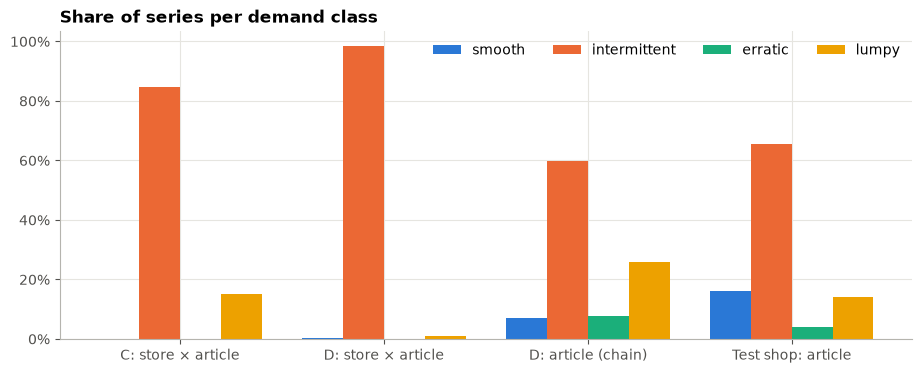

In [33]:
ts = pd.read_parquet(BASE / 'test-shop' / 'history.parquet')
ts['week_start'] = pd.to_datetime(ts['week_start'])

series = {
    'C: store × article':  demand_classes(c_daily, PAIR, 'date', g['date'].max()),
    'D: store × article':  demand_classes(d_sales, PAIR, 'date', D_END),
    'D: article (chain)':  demand_classes(d_sales, ['article_id'], 'date', D_END),
    'Test shop: article':  demand_classes(ts, ['article_id'], 'week_start', ts.week_start.max()),
}
CLASSES = ['smooth', 'intermittent', 'erratic', 'lumpy']
cmp = pd.DataFrame({name: {
    'series': len(st),
    'median_weeks_span': st.span_weeks.median(),
    'zero_weeks_%': round(100 * (1 - st.nonzero_weeks.sum() / st.span_weeks.sum()), 1),
    'median_units_per_sale_week': st.mean_nz.median(),
    **{f'{c}_%': round(100 * (st['class'] == c).mean(), 1) for c in CLASSES}} for name, st in series.items()}).T
display(cmp)
print('Test shop articles that never sold (not in the table above):', ts.article_id.nunique() - len(series['Test shop: article']))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(series)); wdt = 0.2
for i, c in enumerate(CLASSES):
    ax.bar(x + (i - 1.5) * wdt, cmp[f'{c}_%'], width=wdt, color=CAT[i], label=c)
ax.set_xticks(x, cmp.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Share of series per demand class'); ax.legend(frameon=False, ncol=4)
plt.show()

## Overall takeaways

**How C and D relate to the test shop**
- Weekly article series in the test shop: 58% zero weeks, 16% smooth, 66% intermittent, 14% lumpy. **Set D at article × week (chain)** is the closest match (50% zero weeks, 7% smooth, 60% intermittent, 26% lumpy).
- Set C (store × article × week) is closer to the test shop's slow tail: 74% zero weeks, 85% intermittent.

**If C and D are used as extra training data (e.g. for a global LightGBM model on lag features)**
1. Aggregate to **weeks starting Monday**, the same convention as the test shop.
2. **Set D**: use article × week (chain), or store × category × week. Store × article is almost all zeros.
3. **Set C**: use store × article × week, but only inside each pair's listed periods (missing rows are not zeros).
4. **Remove leaky or unreliable columns**:
   - Set C: `is_phasing_out` and same-day `days_since_sale`. Lagging them is fine.
   - Set C: `latest_on_hand` and raw `on_hand`.
   - Set D: stock before ~autumn 2025.
5. **Clean outliers**: PROD-0000202 at STR-022 in Set C, and price glitches (0 or ~1000) in Set C `unit_price`.
6. Calendar effects such as Black Friday, Christmas and June are real in C and D. They **don't transfer by date** to the test shop, whose dates are shifted. Learn seasonality from 52-week lags instead.
7. Set C has ~2.3 years of history and Set D only ~11 months, so Set D can't teach yearly seasonality.